## Experimental on Variance-Guided Scalar Projection (VGSP)
#### Version 4
##### Designed by **Mohd Adil Mokti**, Center for Cyber Security, National University of Malaysia
###### Latest update: 13/11/2026 05:00 PM

**Research focus:** CVR-guided one-dimensional traffic representation for lightweight DDoS detection in Software-Defined Networks (SDN).

**Datasets:** InSDN and DDOSDN2025.

#### Figure 2: VGSP Methodology and Evaluation Workflow

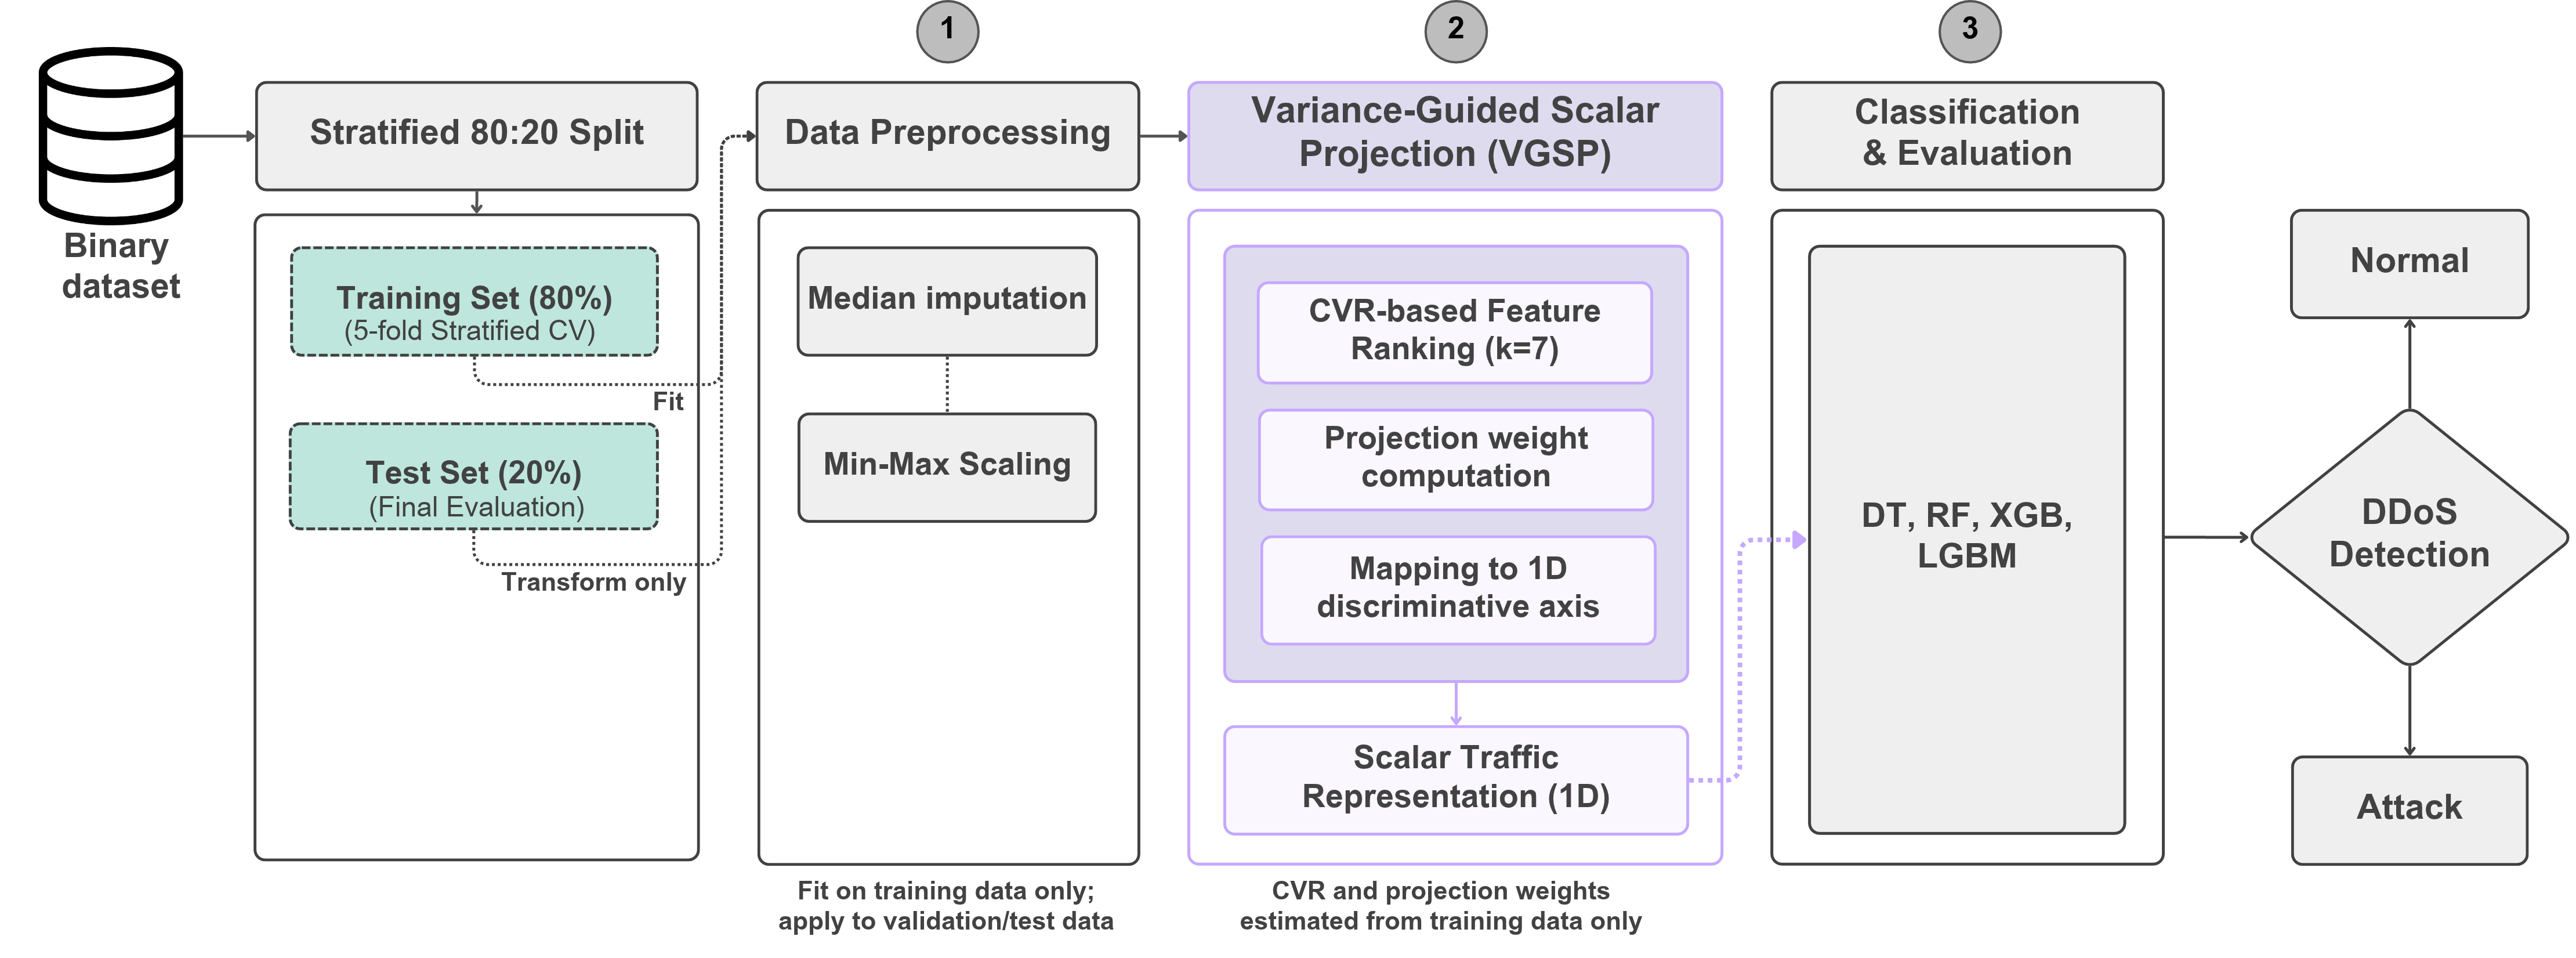

#### 1. Libraries and experimental configuration

**Procedure:** Establish a reproducible, shared configuration for the subsequent VGSP experiments.

In [1]:
# CELL 1: LIBRARIES & CONFIGURATION
# ============================================================

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    StratifiedGroupKFold
)
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    auc
)

from scipy.stats import wilcoxon
from threadpoolctl import threadpool_limits

import xgboost as xgb
import lightgbm as lgb

from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# CONFIGURATION
# ============================================================

RANDOM_STATE = 42
N_FOLDS = 5
CVR_EPSILON = 1e-10
K_VALUES = range(1, 13)
N_THREADS = 1

# Dataset paths
INSDN_PATH = Path("../ds/insdn_ddos_binary_0n1d.csv")
DDOSDN_PATH = Path("../ds/ddosdn2025_binary_0n1d.csv")

# Results
OUTPUT_DIR = Path("vgsp_resultsv4")
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.6f}".format)

np.random.seed(RANDOM_STATE)

print("Libraries and configuration were initialized.")


Libraries and configuration were initialized.


#### 2. Load and describe the binary datasets

Prepare numeric feature matrices and binary labels, and document the data used in the experiments.

**Procedure:** Read the two previously prepared binary CSVs; remove the label and available identifier/metadata columns from X; map infinite feature values to missing values; and form integer labels 0=Normal, 1=DDoS. A hash of each complete feature vector is created to describe duplicate vectors and groups with conflicting labels.


In [2]:
# CELL 2: DATASET LOADING & CLEANING
# ============================================================

paths = {
    "InSDN": INSDN_PATH,
    "DDOSDN2025": DDOSDN_PATH
}

metadata = [
    "src_ip", "dst_ip", "src_port", "dst_port",
    "timestamp", "Label_multi", "Attack_Type"
]

datasets = {}

for name, path in paths.items():

    df = pd.read_csv(path, low_memory=False)

    # Separate features and labels
    X = df.drop(
        columns=["Label"] + [c for c in metadata if c in df.columns]
    ).replace([np.inf, -np.inf], np.nan)

    y = df["Label"].astype(int).to_numpy()

    # Group identical feature vectors
    groups = pd.util.hash_pandas_object(
        X, index=False
    ).to_numpy()

    # Check conflicting labels
    conflicts = (
        pd.DataFrame({"group": groups, "label": y})
        .groupby("group")["label"].nunique().gt(1).sum()
    )

    datasets[name] = {
        "X": X,
        "y": y,
        "groups": groups,
        "attack_type": (
            df["Attack_Type"].to_numpy()
            if "Attack_Type" in df else None
        )
    }

    n_unique = len(np.unique(groups))

    print(f"\n{'=' * 55}")
    print(f"Dataset: {name}")
    print(f"{'=' * 55}")
    print(f"Records           : {len(df):,}")
    print(f"Features          : {X.shape[1]}")
    print(f"Normal            : {(y == 0).sum():,}")
    print(f"DDoS              : {(y == 1).sum():,}")
    print(f"Unique vectors    : {n_unique:,}")
    print(f"Duplicates        : {len(df) - n_unique:,}")
    print(f"Conflicting groups: {conflicts}")
    print(f"Missing values    : {X.isna().sum().sum():,}")

print("\nDataset loading and cleaning completed.")



Dataset: InSDN
Records           : 190,366
Features          : 77
Normal            : 68,424
DDoS              : 121,942
Unique vectors    : 65,634
Duplicates        : 124,732
Conflicting groups: 0
Missing values    : 0

Dataset: DDOSDN2025
Records           : 200,378
Features          : 77
Normal            : 46,077
DDoS              : 154,301
Unique vectors    : 54,484
Duplicates        : 145,894
Conflicting groups: 5
Missing values    : 0

Dataset loading and cleaning completed.


**Summary:** InSDN contains 190,366 records and 77 numeric features; DDOSDN2025 contains 200,378 records and 77 features. Both feature matrices report zero missing values after the specified replacement.

#### 3. Stratified development and held-out test partitions

Separate data used for development/model selection from data reserved for final testing.

**Procedure:** For each dataset, create an 80:20 partition with train_test_split(..., stratify=y, random_state=42). Save positional indices as dev_idx and test_idx. This division precedes any fitted preprocessing, CVR calculation, feature ranking or classifier training.

In [3]:
# CELL 3: DEVELOPMENT & TEST SPLITTING
# ============================================================

TEST_SIZE = 0.20

for name, data in datasets.items():

    y = data["y"]
    indices = np.arange(len(y))

    dev_idx, test_idx = train_test_split(
        indices,
        test_size=TEST_SIZE,
        stratify=y,
        random_state=RANDOM_STATE
    )

    data["dev_idx"] = dev_idx
    data["test_idx"] = test_idx

    print(f"\n{'=' * 50}")
    print(f"Dataset: {name}")
    print(f"{'=' * 50}")
    print(f"Development : {len(dev_idx):,} ({len(dev_idx)/len(y)*100:.2f}%)")
    print(f"Test        : {len(test_idx):,} ({len(test_idx)/len(y)*100:.2f}%)")
    print(f"Dev DDoS    : {y[dev_idx].mean()*100:.2f}%")
    print(f"Test DDoS   : {y[test_idx].mean()*100:.2f}%")

print("\nPartition completed.")



Dataset: InSDN
Development : 152,292 (80.00%)
Test        : 38,074 (20.00%)
Dev DDoS    : 64.06%
Test DDoS   : 64.06%

Dataset: DDOSDN2025
Development : 160,302 (80.00%)
Test        : 40,076 (20.00%)
Dev DDoS    : 77.00%
Test DDoS   : 77.01%

Partition completed.


**Summary:**

- **InSDN:** 152,292 development and 38,074 test records, with approximately 64.06% DDoS in both partitions.
- **DDOSDN2025:** 160,302 development and 40,076 test records, with approximately 77.00%/77.01% DDoS, respectively. 
- The planned 80:20 stratified partitions were created without fitting model parameters or accessing the test labels for model selection.

#### 4. Define the VGSP algorithm

Implement the proposed training-fitted projection from a multi-feature traffic vector to one scalar.

In [4]:
# CELL 4: VARIANCE-GUIDED SCALAR PROJECTION (VGSP)
# ============================================================

def fit_vgsp(X, y, k, eps=CVR_EPSILON):

    # Level I: CVR Discriminative Weight Derivation
    X = np.asarray(X)
    y = np.asarray(y)

    X0, X1 = X[y == 0], X[y == 1]
    p0, p1 = len(X0) / len(X), len(X1) / len(X)

    W = p0 * X0.var(axis=0) + p1 * X1.var(axis=0)
    B = p0 * p1 * (X0.mean(axis=0) - X1.mean(axis=0))**2

    cvr = B / (B + W + eps)

    # Level II: CVR-Guided Scalar Projection
    idx = np.argsort(-cvr, kind="stable")[:k]
    weights = cvr[idx] / (cvr[idx].sum() + eps)

    return {
        "indices": idx,
        "weights": weights,
        "cvr": cvr,
        "eps": eps
    }


def transform_vgsp(X, model, k=None):

    idx = model["indices"][:k]
    scores = model["cvr"][idx]
    weights = scores / (scores.sum() + model["eps"])

    return (np.asarray(X)[:, idx] @ weights).reshape(-1, 1)


print("VGSP loaded.")


VGSP loaded.


#### 5. Select the feature count k using InSDN development CV

Determine a fixed feature count without consulting the final held-out test set.

**Procedure:** Apply five-fold StratifiedKFold to InSDN development data only. Within each fold, fit the median imputer, zero-variance filter (VarianceThreshold) and MinMax scaler on the fold's training subset. Fit CVR ranking once on that training subset, evaluate projections for each k=1,…,12 using a Decision Tree, and compute validation Macro-F1 and Accuracy. Summarize the five validation folds using their mean Macro-F1, standard deviation and minimum. DT is used solely as the fixed classifier for feature-count determination; the representation is later evaluated with four classifiers.

Fold 1/5 completed
Fold 2/5 completed
Fold 3/5 completed
Fold 4/5 completed
Fold 5/5 completed

INSDN FEATURE-COUNT ABLATION — PREDICTIVE PERFORMANCE
       mean      std      min  accuracy  Accuracy_SD      MCC  ROC_AUC   PR_AUC       AP
k                                                                                       
1  0.994904 0.000328 0.994514  0.995305     0.000303 0.989810 0.996166 0.997982 0.995984
2  0.995269 0.000418 0.994657  0.995640     0.000385 0.990541 0.997375 0.998544 0.997104
3  0.998194 0.000180 0.997966  0.998339     0.000165 0.996395 0.997744 0.997552 0.997475
4  0.998202 0.000146 0.998037  0.998345     0.000135 0.996409 0.997726 0.996248 0.997455
5  0.998209 0.000159 0.998037  0.998352     0.000146 0.996423 0.997744 0.997552 0.997475
6  0.998573 0.000749 0.998073  0.998687     0.000689 0.997150 0.998207 0.996656 0.997997
7  0.999943 0.000032 0.999893  0.999947     0.000029 0.999886 0.999956 0.999981 0.999961
8  0.999893 0.000067 0.999822  0.999902     0.000

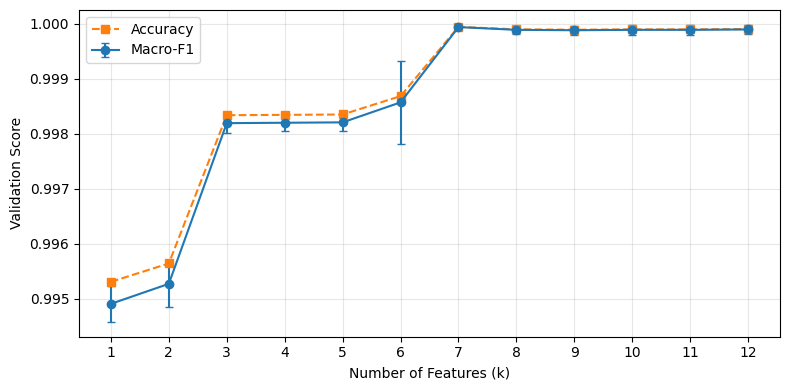


Feature count ablation completed.



**Summary:** Five-fold development CV selected **k=7** with mean **Macro-F1 0.999943 ± 0.000032**, Accuracy 0.999947, MCC 0.999886, and ROC-AUC 0.999956. The average total training time was **1.523617s**.

In [5]:
# CELL 5: FEATURE-COUNT ABLATION (INSDN)
# ============================================================
# Same stratified development CV and training-only VGSP as v4.
# Added requested metrics and feature-level computational timings.

data = datasets["InSDN"]
X, y = data["X"], data["y"]
dev_idx = data["dev_idx"]

cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

k_results = []

for fold, (tr, va) in enumerate(
    cv.split(X.iloc[dev_idx], y[dev_idx]), start=1
):
    tr, va = dev_idx[tr], dev_idx[va]
    ytr, yva = y[tr], y[va]

    # Training-only preprocessing (fitted once per fold)
    t0 = time.perf_counter()
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    X_train = imputer.fit_transform(X.iloc[tr])
    vt = VarianceThreshold()
    X_train = vt.fit_transform(X_train)
    scaler = MinMaxScaler()
    X_train = scaler.fit_transform(X_train)
    preprocess_train = time.perf_counter() - t0

    # Apply unchanged training-fitted transforms to validation
    t0 = time.perf_counter()
    X_valid = imputer.transform(X.iloc[va])
    X_valid = vt.transform(X_valid)
    X_valid = scaler.transform(X_valid)
    preprocess_valid = time.perf_counter() - t0

    # CVR fitting/ranking shared by k=1..12, on training only
    t0 = time.perf_counter()
    vgsp = fit_vgsp(X_train, ytr, k=max(K_VALUES))
    cvr_fit = time.perf_counter() - t0

    for k in K_VALUES:
        # Scalar projection costs for each k
        t0 = time.perf_counter()
        Z_train = transform_vgsp(X_train, vgsp, k=k)
        projection_train = time.perf_counter() - t0

        t0 = time.perf_counter()
        Z_valid = transform_vgsp(X_valid, vgsp, k=k)
        projection_valid = time.perf_counter() - t0

        dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
        t0 = time.perf_counter()
        dt.fit(Z_train, ytr)
        classifier_train = time.perf_counter() - t0

        t0 = time.perf_counter()
        y_pred = dt.predict(Z_valid)
        classifier_inference = time.perf_counter() - t0

        # Continuous positive-class scores; not timed as classifier inference
        scores = dt.predict_proba(Z_valid)[:, 1]
        precision_curve, recall_curve, _ = precision_recall_curve(yva, scores)

        # Feature-level pipeline only; excludes packet capture/extraction
        total_train = (
            preprocess_train + cvr_fit + projection_train + classifier_train
        )
        total_inference = (
            preprocess_valid + projection_valid + classifier_inference
        )

        k_results.append({
            "Fold": fold,
            "k": k,
            "Macro-F1": f1_score(yva, y_pred, average="macro"),
            "Accuracy": accuracy_score(yva, y_pred),
            "MCC": matthews_corrcoef(yva, y_pred),
            "ROC-AUC": roc_auc_score(yva, scores),
            "PR-AUC": auc(recall_curve, precision_curve),
            "AP": average_precision_score(yva, scores),
            "Preprocess Train (s)": preprocess_train,
            "CVR Fit (s)": cvr_fit,
            "Projection Train (s)": projection_train,
            "DT Train (s)": classifier_train,
            "Total Train (s)": total_train,
            "Preprocess Valid (s)": preprocess_valid,
            "Projection Valid (s)": projection_valid,
            "DT Inference (s)": classifier_inference,
            "Total Inference (s)": total_inference,
            "Inference (us/sample)": total_inference / len(yva) * 1e6
        })

    print(f"Fold {fold}/{N_FOLDS} completed")

# ============================================================
# FOLD-WISE RESULTS AND FEATURE-COUNT SUMMARY
# ============================================================
k_results_df = pd.DataFrame(k_results)

k_summary_df = (
    k_results_df.groupby("k")
    .agg(
        mean=("Macro-F1", "mean"),
        std=("Macro-F1", "std"),
        min=("Macro-F1", "min"),
        accuracy=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", "std"),
        MCC=("MCC", "mean"),
        ROC_AUC=("ROC-AUC", "mean"),
        PR_AUC=("PR-AUC", "mean"),
        AP=("AP", "mean"),
        Preprocess_Train_s=("Preprocess Train (s)", "mean"),
        CVR_Fit_s=("CVR Fit (s)", "mean"),
        Projection_Train_s=("Projection Train (s)", "mean"),
        DT_Train_s=("DT Train (s)", "mean"),
        Total_Train_s=("Total Train (s)", "mean"),
        Total_Train_SD_s=("Total Train (s)", "std"),
        Projection_Valid_s=("Projection Valid (s)", "mean"),
        DT_Inference_s=("DT Inference (s)", "mean"),
        Total_Inference_s=("Total Inference (s)", "mean"),
        Inference_us=("Inference (us/sample)", "mean"),
        Inference_SD_us=("Inference (us/sample)", "std")
    )
)

print("\nINSDN FEATURE-COUNT ABLATION — PREDICTIVE PERFORMANCE")
print(k_summary_df[[
    "mean", "std", "min", "accuracy", "Accuracy_SD", "MCC",
    "ROC_AUC", "PR_AUC", "AP"
]].round(6).to_string())

print("\nINSDN FEATURE-COUNT ABLATION — COMPUTATIONAL EFFICIENCY")
print(k_summary_df[[
    "Preprocess_Train_s", "CVR_Fit_s", "Projection_Train_s",
    "DT_Train_s", "Total_Train_s", "Total_Train_SD_s",
    "Projection_Valid_s", "DT_Inference_s", "Total_Inference_s",
    "Inference_us", "Inference_SD_us"
]].round(6).to_string())

# Keep the original k-selection plot unchanged
plt.figure(figsize=(8, 4))
plt.errorbar(
    k_summary_df.index, k_summary_df["mean"],
    yerr=k_summary_df["std"], marker="o", capsize=3,
    label="Macro-F1"
)
plt.plot(
    k_summary_df.index, k_summary_df["accuracy"],
    marker="s", linestyle="--", label="Accuracy"
)
plt.xlabel("Number of Features (k)")
plt.ylabel("Validation Score")
plt.xticks(list(K_VALUES))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "insdn_k_ablation.png", dpi=300, bbox_inches="tight")
plt.show()

k_summary_df.to_csv(OUTPUT_DIR / "insdn_k_ablation.csv")
k_results_df.to_csv(OUTPUT_DIR / "insdn_k_fold_scores.csv", index=False)

print("\nFeature count ablation completed.\n")

best_k = int(k_summary_df["mean"].idxmax())
best = k_summary_df.loc[best_k]

display(Markdown(
    f"**Summary:** Five-fold development CV selected **k={best_k}** "
    f"with mean **Macro-F1 {best['mean']:.6f} ± {best['std']:.6f}**, "
    f"Accuracy {best['accuracy']:.6f}, MCC {best['MCC']:.6f}, "
    f"and ROC-AUC {best['ROC_AUC']:.6f}. "
    f"The average total training time was "
    f"**{best['Total_Train_s']:.6f}s**."
))

##### Why choose DT as primary classifier for selection of k:
Decision Tree (DT) was adopted as the primary classifier for feature-count determination due to its low computational complexity and suitability for lightweight DDoS detection. The optimal feature count was determined using validation Macro-F1 with DT and subsequently fixed for all classifiers to ensure a consistent comparison of the VGSP representation. RF, XGB, and LGBM were additionally evaluated to assess the effectiveness of the resulting scalar representation across different classifiers.

#### 6. Freeze k, estimate development ranking, and examine correlations

Freeze the feature count chosen in Cell 5 and describe the selected InSDN features before the later comparisons.

Set **FIXED_K** to the value that maximizes development CV mean Macro-F1. Fit median imputation, a zero-variance filter, MinMax scaling and VGSP on the entire InSDN development partition only, then report selected feature names, original-column indices, CVR scores, and normalized weights. Visualize pairwise Pearson correlations of the selected, scaled features.

Selected k       : 7
Validation F1    : 0.999943
Fold SD          : 0.000032
Validation Acc   : 0.999947

CVR FEATURE RANKING
 Rank  Feature Index           Feature  CVR Score   Weight
    1              0          Protocol   0.728136 0.290267
    2             51     Down/Up Ratio   0.536456 0.213855
    3             66 Init Bwd Win Byts   0.336024 0.133954
    4             38       Pkt Len Min   0.287995 0.114808
    5             47      ACK Flag Cnt   0.216327 0.086237
    6             11   Bwd Pkt Len Min   0.202494 0.080723
    7             37        Bwd Pkts/s   0.201074 0.080157


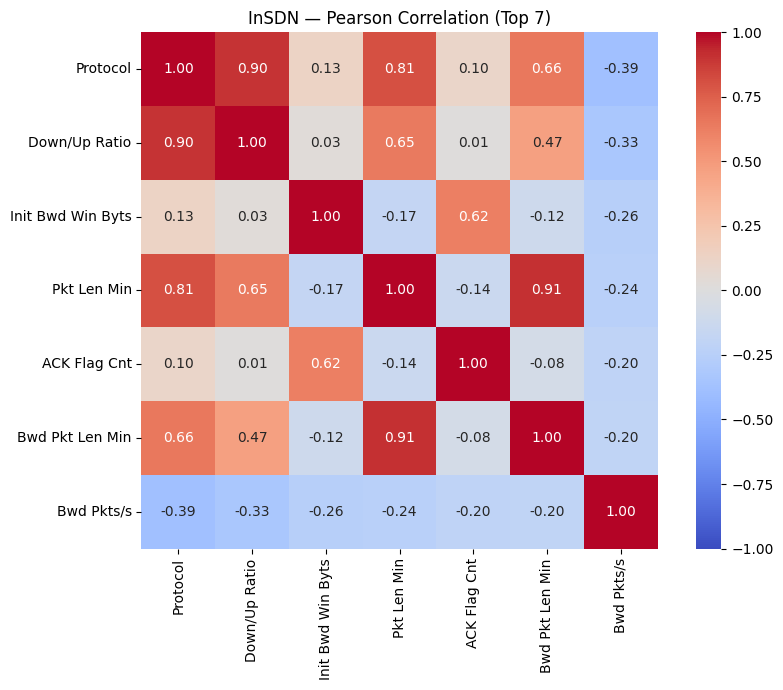


Ranking and correlation completed.


In [6]:
# CELL 6: FIXED-k, CVR RANKING & CORRELATION HEATMAP
# ============================================================

# Select k based on InSDN validation Macro-F1
FIXED_K = int(k_summary_df["mean"].idxmax())

print(f"Selected k       : {FIXED_K}")
print(f"Validation F1    : {k_summary_df.loc[FIXED_K, 'mean']:.6f}")
print(f"Fold SD          : {k_summary_df.loc[FIXED_K, 'std']:.6f}")
print(f"Validation Acc   : {k_summary_df.loc[FIXED_K, 'accuracy']:.6f}")

# InSDN development data
data = datasets["InSDN"]
X = data["X"].iloc[data["dev_idx"]]
y = data["y"][data["dev_idx"]]

# Training-only preprocessing
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_scaled = imputer.fit_transform(X)

vt = VarianceThreshold()
X_scaled = vt.fit_transform(X_scaled)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_scaled)

# Fit VGSP
vgsp = fit_vgsp(X_scaled, y, k=FIXED_K)

idx = vgsp["indices"]
features = X.columns[vt.get_support()]
selected = features[idx]

# CVR ranking table
ranking_df = pd.DataFrame({
    "Rank": range(1, FIXED_K + 1),
    "Feature Index": X.columns.get_indexer(selected),
    "Feature": selected,
    "CVR Score": vgsp["cvr"][idx],
    "Weight": vgsp["weights"]
})

print("\nCVR FEATURE RANKING")
print(ranking_df.to_string(index=False))

ranking_df.to_csv(
    OUTPUT_DIR / "insdn_cvr_ranking.csv", index=False
)

# Pearson correlation heatmap
corr = pd.DataFrame(
    X_scaled[:, idx], columns=selected
).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(f"InSDN — Pearson Correlation (Top {FIXED_K})")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "insdn_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nRanking and correlation completed.")


**Summary:** **FIXED_K=7** with InSDN validation Macro-F1 **0.999943 (SD 0.000032)**. The seven ranked features are **Protocol, Down/Up Ratio, Init Bwd Win Byts, Pkt Len Min, ACK Flag Cnt, Bwd Pkt Len Min, and Bwd Pkts/s**. Protocol has the largest development CVR score (0.728136) and normalized weight (0.290267).

#### 7. Protocol encoding and correlated-feature sensitivity analyses

Examine whether the fixed seven-feature VGSP representation depends on Protocol treatment or on individual highly correlated features, as requested in the editor's Protocol/correlation comments.

Define the seven feature names obtained from Cell 6. On the InSDN development partition, identify Pearson pairs with |r| ≥ 0.80; then use five-fold stratified CV to compare: original fixed-seven VGSP, no Protocol, one-hot-encoded Protocol, removal of each selected correlated feature (except Protocol in the pair-derived list), and joint removal of the two packet-length-minimum features. Each fold fits its imputer, scaler, one-hot encoder where applicable, CVR weights and DT using training observations only.

In [7]:
# CELL 7: PROTOCOL & CORRELATED FEATURE ABLATION
# ============================================================

from sklearn.preprocessing import OneHotEncoder

data = datasets["InSDN"]
features = ranking_df["Feature"].tolist()
X = data["X"][features]
y = data["y"]
dev = data["dev_idx"]

CORR_THRESHOLD = 0.80

# ============================================================
# 1. IDENTIFY HIGHLY CORRELATED FEATURES
# ============================================================

imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_dev = imputer.fit_transform(X.iloc[dev])
X_dev = MinMaxScaler().fit_transform(X_dev)

corr = pd.DataFrame(X_dev, columns=features).corr()

pairs = [
    (features[i], features[j], corr.iloc[i, j])
    for i in range(len(features))
    for j in range(i + 1, len(features))
    if abs(corr.iloc[i, j]) >= CORR_THRESHOLD
]

corr_df = pd.DataFrame(
    pairs, columns=["Feature A", "Feature B", "Pearson r"]
).sort_values("Pearson r", key=abs, ascending=False)

print(f"\nHIGH CORRELATION PAIRS (|r| >= {CORR_THRESHOLD})")
print(corr_df.to_string(
    index=False,
    formatters={"Pearson r": "{:.3f}".format}
))

# Test removal of every correlated feature
drop_features = list(dict.fromkeys(
    f for a, b, _ in pairs for f in (a, b)
    if f != "Protocol"
))

# ============================================================
# 2. FEATURE ABLATION (5-FOLD CV)
# ============================================================

cv = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE
)

ablation_results = []

for fold, (tr, va) in enumerate(
    cv.split(X.iloc[dev], y[dev]), start=1
):

    tr, va = dev[tr], dev[va]

    # Training-only preprocessing
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    Xtr = imputer.fit_transform(X.iloc[tr])
    Xva = imputer.transform(X.iloc[va])

    scaler = MinMaxScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(Xtr), columns=features)
    Xva = pd.DataFrame(scaler.transform(Xva), columns=features)

    # One-hot Protocol
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    Ptr = encoder.fit_transform(X.iloc[tr][["Protocol"]])
    Pva = encoder.transform(X.iloc[va][["Protocol"]])

    # Experimental configurations
    configs = {
        "Original VGSP": (Xtr.to_numpy(), Xva.to_numpy()),
        "Without Protocol": (
            Xtr.drop(columns="Protocol").to_numpy(),
            Xva.drop(columns="Protocol").to_numpy()
        ),
        "Protocol Only": (
            Xtr[["Protocol"]].to_numpy(),
            Xva[["Protocol"]].to_numpy()
        ),
        "One-Hot Protocol": (
            np.column_stack([Xtr.drop(columns="Protocol"), Ptr]),
            np.column_stack([Xva.drop(columns="Protocol"), Pva])
        )
    }

    for feature in drop_features:
        configs[f"Without {feature}"] = (
            Xtr.drop(columns=feature).to_numpy(),
            Xva.drop(columns=feature).to_numpy()
        )
        # Remove both highly correlated packet-length features
        configs["Without Both Pkt Len Min"] = (
            Xtr.drop(columns=["Pkt Len Min", "Bwd Pkt Len Min"]).to_numpy(),
            Xva.drop(columns=["Pkt Len Min", "Bwd Pkt Len Min"]).to_numpy()
        )

    for method, (A, B) in configs.items():

        vgsp = fit_vgsp(A, y[tr], k=A.shape[1])
        Ztr = transform_vgsp(A, vgsp)
        Zva = transform_vgsp(B, vgsp)

        dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
        dt.fit(Ztr, y[tr])

        pred = dt.predict(Zva)
        tn, fp, fn, tp = confusion_matrix(
            y[va], pred, labels=[0, 1]
        ).ravel()

        ablation_results.append({
            "Method": method,
            "Fold": fold,
            "Features": A.shape[1],
            "Accuracy": accuracy_score(y[va], pred),
            "Macro-F1": f1_score(y[va], pred, average="macro"),
            "MCC": matthews_corrcoef(y[va], pred),
            "Recall": recall_score(y[va], pred),
            "FPR": fp / (fp + tn)
        })

    print(f"Fold {fold}/{N_FOLDS} completed")

# ============================================================
# 3. RESULTS
# ============================================================

ablation_df = pd.DataFrame(ablation_results)

ablation_summary_df = (
    ablation_df.groupby("Method", sort=False)
    .agg(
        Features=("Features", "first"),
        Accuracy=("Accuracy", "mean"),
        Macro_F1=("Macro-F1", "mean"),
        F1_SD=("Macro-F1", "std"),
        MCC=("MCC", "mean"),
        Recall=("Recall", "mean"),
        FPR=("FPR", "mean")
    )
)

print("\nINSDN PROTOCOL & FEATURE ABLATION")
print(ablation_summary_df.to_string(
    formatters={
        c: "{:.6f}".format
        for c in ablation_summary_df.columns
        if c != "Features"
    }
))

corr_df.to_csv(OUTPUT_DIR / "insdn_high_correlations.csv", index=False)
ablation_df.to_csv(OUTPUT_DIR / "insdn_ablation_folds.csv", index=False)
ablation_summary_df.to_csv(OUTPUT_DIR / "insdn_ablation_summary.csv")

print("\nSensitivity analysis completed.\n")

a = ablation_summary_df

original = a.loc["Original VGSP"]
protocol_only = a.loc["Protocol Only"]
without_protocol = a.loc["Without Protocol"]
onehot = a.loc["One-Hot Protocol"]
without_both = a.loc["Without Both Pkt Len Min"]

display(Markdown(
    f"**Summary:** Original VGSP achieved Macro-F1 "
    f"**{original['Macro_F1']:.6f}**, compared with "
    f"{protocol_only['Macro_F1']:.6f} using Protocol alone, "
    f"{without_protocol['Macro_F1']:.6f} without Protocol, "
    f"and {onehot['Macro_F1']:.6f} using one-hot encoding. "
    f"Removing both packet-length minimum features resulted in "
    f"Macro-F1 {without_both['Macro_F1']:.6f}, "
    f"indicating their contribution can be evaluated "
    f"without assuming that all selected features are essential."
))


HIGH CORRELATION PAIRS (|r| >= 0.8)
  Feature A       Feature B Pearson r
Pkt Len Min Bwd Pkt Len Min     0.906
   Protocol   Down/Up Ratio     0.903
   Protocol     Pkt Len Min     0.807
Fold 1/5 completed
Fold 2/5 completed
Fold 3/5 completed
Fold 4/5 completed
Fold 5/5 completed

INSDN PROTOCOL & FEATURE ABLATION
                          Features Accuracy Macro_F1    F1_SD      MCC   Recall      FPR
Method                                                                                  
Original VGSP                    7 0.999947 0.999943 0.000032 0.999886 0.999938 0.000037
Without Protocol                 6 0.999770 0.999750 0.000110 0.999501 0.999877 0.000420
Protocol Only                    1 0.995305 0.994904 0.000328 0.989810 0.995756 0.005499
One-Hot Protocol                 9 0.999783 0.999765 0.000093 0.999529 0.999856 0.000347
Without Down/Up Ratio            6 0.999803 0.999786 0.000076 0.999572 0.999836 0.000256
Without Both Pkt Len Min         5 0.999947 0.999943 0.000

**Summary:** Original VGSP achieved Macro-F1 **0.999943**, compared with 0.994904 using Protocol alone, 0.999750 without Protocol, and 0.999765 using one-hot encoding. Removing both packet-length minimum features resulted in Macro-F1 0.999943, indicating their contribution can be evaluated without assuming that all selected features are essential.

This indicate that VGSP performance does not depend solely on Protocol. One-hot encoding provided no improvement over the original configuration. Removing Down/Up Ratio slightly reduced performance, whereas removing Pkt Len Min, Bwd Pkt Len Min, or both produced identical results, suggesting feature redundancy. Overall, the ablation confirms the effectiveness of the original VGSP configuration while identifying features with potentially overlapping contributions.

#### 8. Compare VGSP with common feature-selection/projection baselines

Evaluate the contribution and computational footprint of the scalar representation under a shared InSDN development-CV setup.

Compare Full-DT (77 features), VT-7D-DT, FS-7D-DT, PCA-1D-DT, LDA-1D-DT and VGSP-1D-DT. Each method receives its training-fold-fitted imputer and MinMax scaler; feature selection or projection fitting uses only the training fold. Every method uses the same five stratified folds and Decision Tree classifier. Report validation prediction metrics, fold variability, separate preprocessing/selection/projection/classifier times, and DT node/depth statistics.

In [8]:
# CELL 8: VGSP METHOD VALIDATION (INSDN ONLY)
# 77D -> 77D / 7D / 1D
# ============================================================

data = datasets["InSDN"]
X, y = data["X"], data["y"]
dev = data["dev_idx"]

METHODS = [
    "Full-DT",
    "VT-7D-DT",
    "FS-7D-DT",
    "PCA-1D-DT",
    "LDA-1D-DT",
    "VGSP-1D-DT"
]

cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

method_results = []
method_features = []

for fold, (tr, va) in enumerate(
    cv.split(X.iloc[dev], y[dev]), start=1
):

    tr, va = dev[tr], dev[va]
    ytr, yva = y[tr], y[va]

    # --------------------------------------------------------
    # 1. COMMON PREPROCESSING (TRAINING ONLY)
    # --------------------------------------------------------

    t0 = time.perf_counter()

    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )

    A = imputer.fit_transform(X.iloc[tr])

    scaler = MinMaxScaler()
    A = scaler.fit_transform(A)

    preprocess_train = time.perf_counter() - t0

    # Validation uses the training-fitted preprocessing
    t0 = time.perf_counter()

    B = imputer.transform(X.iloc[va])
    B = scaler.transform(B)

    preprocess_test = time.perf_counter() - t0

    # --------------------------------------------------------
    # 2. EVALUATE EACH METHOD
    # --------------------------------------------------------

    for method in METHODS:

        projection = None
        vgsp_model = None

        # ----------------------------------------------------
        # FEATURE SELECTION / CVR FITTING
        # ----------------------------------------------------

        t0 = time.perf_counter()

        if method == "Full-DT":

            idx = np.arange(A.shape[1])

        elif method == "VT-7D-DT":

            variance = A.var(axis=0)
            valid = np.where(variance > 0)[0]

            idx = valid[
                np.argsort(
                    -variance[valid],
                    kind="stable"
                )[:FIXED_K]
            ]

        elif method == "FS-7D-DT":

            A0 = A[ytr == 0]
            A1 = A[ytr == 1]

            p0 = len(A0) / len(A)
            p1 = len(A1) / len(A)

            within = (
                p0 * A0.var(axis=0) +
                p1 * A1.var(axis=0)
            )

            between = (
                p0 * p1 *
                (A0.mean(axis=0) - A1.mean(axis=0))**2
            )

            fisher = between / (within + CVR_EPSILON)

            valid = np.where(A.var(axis=0) > 0)[0]

            idx = valid[
                np.argsort(
                    -fisher[valid],
                    kind="stable"
                )[:FIXED_K]
            ]

        elif method == "VGSP-1D-DT":

            # CVR ranking + weight estimation
            # from training data only
            vgsp_model = fit_vgsp(
                A, ytr, k=FIXED_K
            )

            idx = vgsp_model["indices"]

        else:

            # PCA and LDA use all original 77 features
            idx = np.arange(A.shape[1])

        selection_time = time.perf_counter() - t0

        if len(idx) < FIXED_K:
            raise ValueError(
                f"{method}: insufficient selected features"
            )

        method_features.append({
            "Fold": fold,
            "Method": method,
            "Input Features": len(idx),
            "Selected Features": ", ".join(X.columns[idx])
        })

        # ----------------------------------------------------
        # 3. REPRESENTATION FITTING
        # ----------------------------------------------------

        t0 = time.perf_counter()

        if method == "PCA-1D-DT":

            projection = PCA(n_components=1)
            projection.fit(A)

        elif method == "LDA-1D-DT":

            projection = LinearDiscriminantAnalysis(
                n_components=1
            )
            projection.fit(A, ytr)

        # VGSP weight fitting already measured
        # in selection_time above.

        representation_fit = time.perf_counter() - t0

        # ----------------------------------------------------
        # 4. TRAINING REPRESENTATION
        # ----------------------------------------------------

        t0 = time.perf_counter()

        if method == "Full-DT":

            Ztr = A

        elif method in ["VT-7D-DT", "FS-7D-DT"]:

            Ztr = A[:, idx]

        elif method in ["PCA-1D-DT", "LDA-1D-DT"]:

            Ztr = projection.transform(A)

        else:

            Ztr = transform_vgsp(A, vgsp_model)

        projection_train = time.perf_counter() - t0

        # ----------------------------------------------------
        # 5. DECISION TREE TRAINING
        # ----------------------------------------------------

        clf = DecisionTreeClassifier(
            random_state=RANDOM_STATE
        )

        t0 = time.perf_counter()
        clf.fit(Ztr, ytr)
        dt_train = time.perf_counter() - t0

        # ----------------------------------------------------
        # 6. VALIDATION REPRESENTATION
        # ----------------------------------------------------

        t0 = time.perf_counter()

        if method == "Full-DT":

            Zva = B

        elif method in ["VT-7D-DT", "FS-7D-DT"]:

            Zva = B[:, idx]

        elif method in ["PCA-1D-DT", "LDA-1D-DT"]:

            Zva = projection.transform(B)

        else:

            Zva = transform_vgsp(B, vgsp_model)

        projection_test = time.perf_counter() - t0

        # ----------------------------------------------------
        # 7. CLASSIFICATION
        # ----------------------------------------------------

        t0 = time.perf_counter()
        pred = clf.predict(Zva)
        dt_test = time.perf_counter() - t0

        prob = clf.predict_proba(Zva)[:, 1]
        precision_curve, recall_curve, _ = precision_recall_curve(yva, prob)

        tn, fp, fn, tp = confusion_matrix(
            yva, pred, labels=[0, 1]
        ).ravel()

        # ----------------------------------------------------
        # 8. TOTAL COMPUTATIONAL TIME
        # ----------------------------------------------------

        total_train = (
            preprocess_train +
            selection_time +
            representation_fit +
            projection_train +
            dt_train
        )

        total_test = (
            preprocess_test +
            projection_test +
            dt_test
        )

        # ----------------------------------------------------
        # 9. STORE RESULTS
        # ----------------------------------------------------

        method_results.append({

            "Method": method,
            "Fold": fold,
            "Features": Ztr.shape[1],

            # Classification performance
            "Accuracy": accuracy_score(yva, pred),
            "Precision": precision_score(
                yva, pred, zero_division=0
            ),
            "Recall": recall_score(
                yva, pred, zero_division=0
            ),
            "F1": f1_score(
                yva, pred, zero_division=0
            ),
            "Macro-F1": f1_score(
                yva, pred, average="macro"
            ),
            "MCC": matthews_corrcoef(yva, pred),
            "ROC-AUC": roc_auc_score(yva, prob),
            "PR-AUC": auc(recall_curve, precision_curve),
            "AP": average_precision_score(yva, prob),
            "Specificity": tn / (tn + fp),
            "FPR": fp / (fp + tn),
            "FNR": fn / (fn + tp),
            "Balanced Accuracy": balanced_accuracy_score(yva, pred),

            # Training efficiency
            "Preprocess Train (s)": preprocess_train,
            "Selection (s)": selection_time,
            "Representation Fit (s)": representation_fit,
            "Projection Train (s)": projection_train,
            "DT Train (s)": dt_train,
            "Total Train (s)": total_train,

            # Inference efficiency
            "Preprocess Test (s)": preprocess_test,
            "Projection Test (s)": projection_test,
            "DT Test (s)": dt_test,
            "Total Test (s)": total_test,

            "Inference (us/sample)": (
                total_test / len(yva) * 1e6
            ),

            # Model complexity
            "DT Nodes": clf.tree_.node_count,
            "DT Depth": clf.tree_.max_depth

        })

    print(f"Fold {fold}/{N_FOLDS} completed")


# ============================================================
# 10. PERFORMANCE SUMMARY
# ============================================================

method_df = pd.DataFrame(method_results)

performance_df = (
    method_df.groupby("Method", sort=False)
    .agg(
        Features=("Features", "first"),
        Accuracy=("Accuracy", "mean"),
        Precision=("Precision", "mean"),
        Recall=("Recall", "mean"),
        F1=("F1", "mean"),
        Macro_F1=("Macro-F1", "mean"),
        F1_SD=("Macro-F1", "std"),
        MCC=("MCC", "mean"),
        ROC_AUC=("ROC-AUC", "mean"),
        PR_AUC=("PR-AUC", "mean"),
        AP=("AP", "mean"),
        Specificity=("Specificity", "mean"),
        FPR=("FPR", "mean"),
        FNR=("FNR", "mean"),
        Balanced_Accuracy=("Balanced Accuracy", "mean")
    )
)

# ============================================================
# 11. COMPUTATIONAL EFFICIENCY SUMMARY
# ============================================================

efficiency_df = (
    method_df.groupby("Method", sort=False)
    .agg(
        Features=("Features", "first"),

        Preprocess_s=("Preprocess Train (s)", "mean"),
        Selection_s=("Selection (s)", "mean"),
        Representation_s=("Representation Fit (s)", "mean"),
        Projection_Train_s=("Projection Train (s)", "mean"),

        DT_Train_s=("DT Train (s)", "mean"),
        Total_Train_s=("Total Train (s)", "mean"),

        Preprocess_Test_s=("Preprocess Test (s)", "mean"),
        Projection_Test_s=("Projection Test (s)", "mean"),
        DT_Test_s=("DT Test (s)", "mean"),
        Total_Test_s=("Total Test (s)", "mean"),

        Inference_us=("Inference (us/sample)", "mean"),

        DT_Nodes=("DT Nodes", "mean"),
        DT_Depth=("DT Depth", "mean")
    )
)

print("\nINSDN — METHOD PERFORMANCE")
print(performance_df.round(6).to_string())

print("\nINSDN — COMPUTATIONAL EFFICIENCY")
print(efficiency_df.round(6).to_string())


# ============================================================
# 12. SAVE RESULTS
# ============================================================

method_df.to_csv(
    OUTPUT_DIR / "cell8_insdn_method_folds.csv",
    index=False
)

performance_df.to_csv(
    OUTPUT_DIR / "cell8_insdn_performance.csv"
)

efficiency_df.to_csv(
    OUTPUT_DIR / "cell8_insdn_efficiency.csv"
)

pd.DataFrame(method_features).to_csv(
    OUTPUT_DIR / "cell8_insdn_selected_features.csv",
    index=False
)

print("\nEvaluation completed.\n")

v = performance_df.loc["VGSP-1D-DT"]
f = performance_df.loc["Full-DT"]

ve = efficiency_df.loc["VGSP-1D-DT"]
fe = efficiency_df.loc["Full-DT"]

fit_reduction = 100 * (
    1 - ve["DT_Train_s"] / fe["DT_Train_s"]
)

total_reduction = 100 * (
    1 - ve["Total_Train_s"] / fe["Total_Train_s"]
)

display(Markdown(
    f"**Summary:** VGSP-1D-DT achieved mean "
    f"**Macro-F1 {v['Macro_F1']:.6f}**, compared with "
    f"**{f['Macro_F1']:.6f}** for Full-DT, while supplying "
    f"one scalar instead of 77 input dimensions to DT. "
    f"VGSP-DT classifier fitting averaged "
    f"**{ve['DT_Train_s']:.6f}s** versus "
    f"**{fe['DT_Train_s']:.6f}s** for Full-DT "
    f"({fit_reduction:.1f}% reduction). "
    f"Total training averaged **{ve['Total_Train_s']:.6f}s** "
    f"versus **{fe['Total_Train_s']:.6f}s** "
    f"({total_reduction:.1f}% reduction)."
))


Fold 1/5 completed
Fold 2/5 completed
Fold 3/5 completed
Fold 4/5 completed
Fold 5/5 completed

INSDN — METHOD PERFORMANCE
            Features  Accuracy  Precision   Recall       F1  Macro_F1    F1_SD      MCC  ROC_AUC   PR_AUC       AP  Specificity      FPR      FNR  Balanced_Accuracy
Method                                                                                                                                                              
Full-DT           77  0.999947   0.999949 0.999969 0.999959  0.999943 0.000041 0.999886 0.999939 0.999969 0.999938     0.999909 0.000091 0.000031           0.999939
VT-7D-DT           7  0.999869   0.999949 0.999846 0.999897  0.999857 0.000113 0.999715 0.999877 0.999947 0.999893     0.999909 0.000091 0.000154           0.999877
FS-7D-DT           7  0.999869   0.999897 0.999897 0.999897  0.999857 0.000071 0.999715 0.999857 0.999930 0.999861     0.999817 0.000183 0.000103           0.999857
PCA-1D-DT          1  0.999278   0.999395 0.999477 0

**Summary:** VGSP-1D-DT achieved mean **Macro-F1 0.999943**, compared with **0.999943** for Full-DT, while supplying one scalar instead of 77 input dimensions to DT. VGSP-DT classifier fitting averaged **0.071717s** versus **0.859033s** for Full-DT (91.7% reduction). Total training averaged **1.560025s** versus **2.213601s** (29.5% reduction).

#### 9. Four-classifier validation on InSDN VGSP-1D

Check whether the fixed-`k` scalar representation supports lightweight classification and whether a more complex classifier materially improves development-CV performance.

Within each of five stratified InSDN development folds, fit preprocessing and VGSP once on training data, project training and validation features to one scalar, and pass the same representations to DT, RF, XGB and LGBM.

In [9]:
# CELL 9: VGSP CLASSIFIER EVALUATION (INSDN ONLY)
# ============================================================

data = datasets["InSDN"]
X, y = data["X"], data["y"]
dev = data["dev_idx"]

cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

vgsp_costs = []
classifier_results = []
selected_features = []

for fold, (tr, va) in enumerate(
    cv.split(X.iloc[dev], y[dev]), start=1
):

    tr, va = dev[tr], dev[va]
    ytr, yva = y[tr], y[va]

    # ========================================================
    # 1. PREPROCESSING: ONCE PER FOLD
    # ========================================================

    t0 = time.perf_counter()

    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )

    A = imputer.fit_transform(X.iloc[tr])

    scaler = MinMaxScaler()
    A = scaler.fit_transform(A)

    prep_train = time.perf_counter() - t0

    t0 = time.perf_counter()

    B = imputer.transform(X.iloc[va])
    B = scaler.transform(B)

    prep_test = time.perf_counter() - t0

    # ========================================================
    # 2. VGSP: ONCE PER FOLD
    # ========================================================

    t0 = time.perf_counter()

    vgsp = fit_vgsp(A, ytr, k=FIXED_K)

    vgsp_fit = time.perf_counter() - t0

    selected_features.append({
        "Fold": fold,
        "Features": ", ".join(
            X.columns[vgsp["indices"]]
        )
    })

    # Training projection
    t0 = time.perf_counter()

    Ztr = transform_vgsp(A, vgsp)

    projection_train = time.perf_counter() - t0

    # Validation projection
    t0 = time.perf_counter()

    Zva = transform_vgsp(B, vgsp)

    projection_test = time.perf_counter() - t0

    # Shared VGSP computational cost
    vgsp_train = prep_train + vgsp_fit + projection_train
    vgsp_test = prep_test + projection_test

    vgsp_costs.append({
        "Fold": fold,
        "Preprocess Train (s)": prep_train,
        "CVR Fit (s)": vgsp_fit,
        "Projection Train (s)": projection_train,
        "VGSP Train (s)": vgsp_train,
        "Preprocess Test (s)": prep_test,
        "Projection Test (s)": projection_test,
        "VGSP Test (s)": vgsp_test
    })

    # ========================================================
    # 3. FOUR CLASSIFIERS: SAME VGSP-1D INPUT
    # ========================================================

    classifiers = {
        "DT": DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),

        "RF": RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS
        ),

        "XGB": xgb.XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS,
            verbosity=0
        ),

        "LGBM": lgb.LGBMClassifier(
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS,
            verbosity=-1
        )
    }

    for method, clf in classifiers.items():

        # Classifier training
        t0 = time.perf_counter()

        clf.fit(Ztr, ytr)

        clf_train = time.perf_counter() - t0

        # Classifier prediction
        t0 = time.perf_counter()

        pred = clf.predict(Zva)

        clf_test = time.perf_counter() - t0

        prob = clf.predict_proba(Zva)[:, 1]
        precision_curve, recall_curve, _ = precision_recall_curve(yva, prob)

        tn, fp, fn, tp = confusion_matrix(
            yva, pred, labels=[0, 1]
        ).ravel()

        # Total cost for an individual pipeline
        total_train = vgsp_train + clf_train
        total_test = vgsp_test + clf_test

        classifier_results.append({
            "Fold": fold,
            "Classifier": method,
            "Features": Ztr.shape[1],

            # Classification performance
            "Accuracy": accuracy_score(yva, pred),
            "Precision": precision_score(
                yva, pred, zero_division=0
            ),
            "Recall": recall_score(
                yva, pred, zero_division=0
            ),
            "F1": f1_score(
                yva, pred, zero_division=0
            ),
            "Macro-F1": f1_score(
                yva, pred, average="macro"
            ),
            "MCC": matthews_corrcoef(yva, pred),
            "ROC-AUC": roc_auc_score(yva, prob),
            "PR-AUC": auc(recall_curve, precision_curve),
            "AP": average_precision_score(yva, prob),
            "Specificity": tn / (tn + fp),
            "FPR": fp / (fp + tn),
            "FNR": fn / (fn + tp),
            "Balanced Accuracy": balanced_accuracy_score(yva, pred),
            "FP": fp,
            "FN": fn,

            # Computational efficiency
            "Classifier Train (s)": clf_train,
            "Classifier Test (s)": clf_test,
            "Total Train (s)": total_train,
            "Total Test (s)": total_test,
            "Inference (us/sample)": (
                total_test / len(yva) * 1e6
            )
        })

    print(f"Fold {fold}/{N_FOLDS} completed")


# ============================================================
# 4. VGSP REPRESENTATION COST
# ============================================================

vgsp_cost_df = pd.DataFrame(vgsp_costs)

vgsp_cost_summary = (
    vgsp_cost_df.drop(columns="Fold")
    .mean()
    .to_frame(name="Mean (s)")
)

print("\nINSDN — VGSP REPRESENTATION COST")
print(vgsp_cost_summary.round(6).to_string())


# ============================================================
# 5. CLASSIFIER PERFORMANCE
# ============================================================

classifier_df = pd.DataFrame(classifier_results)

classifier_performance_df = (
    classifier_df.groupby("Classifier", sort=False)
    .agg(
        Features=("Features", "first"),
        Accuracy=("Accuracy", "mean"),
        Precision=("Precision", "mean"),
        Recall=("Recall", "mean"),
        F1=("F1", "mean"),
        Macro_F1=("Macro-F1", "mean"),
        F1_SD=("Macro-F1", "std"),
        MCC=("MCC", "mean"),
        ROC_AUC=("ROC-AUC", "mean"),
        PR_AUC=("PR-AUC", "mean"),
        AP=("AP", "mean"),
        Specificity=("Specificity", "mean"),
        FPR=("FPR", "mean"),
        FNR=("FNR", "mean"),
        Balanced_Accuracy=("Balanced Accuracy", "mean"),
        FP=("FP", "sum"),
        FN=("FN", "sum")
    )
)

print("\nINSDN — VGSP CLASSIFIER PERFORMANCE")
print(classifier_performance_df.round(6).to_string())


# ============================================================
# 6. CLASSIFIER COMPUTATIONAL EFFICIENCY
# ============================================================

classifier_efficiency_df = (
    classifier_df.groupby("Classifier", sort=False)
    .agg(
        Features=("Features", "first"),
        Train_s=("Classifier Train (s)", "mean"),
        Test_s=("Classifier Test (s)", "mean"),
        Total_Train_s=("Total Train (s)", "mean"),
        Total_Test_s=("Total Test (s)", "mean"),
        Inference_us=("Inference (us/sample)", "mean")
    )
)

print("\nINSDN — VGSP CLASSIFIER EFFICIENCY")
print(classifier_efficiency_df.round(6).to_string())


# ============================================================
# 7. SAVE RESULTS
# ============================================================

vgsp_cost_df.to_csv(
    OUTPUT_DIR / "cell9_vgsp_cost_folds.csv",
    index=False
)

vgsp_cost_summary.to_csv(
    OUTPUT_DIR / "cell9_vgsp_cost_summary.csv"
)

classifier_df.to_csv(
    OUTPUT_DIR / "cell9_classifier_folds.csv",
    index=False
)

classifier_performance_df.to_csv(
    OUTPUT_DIR / "cell9_classifier_performance.csv"
)

classifier_efficiency_df.to_csv(
    OUTPUT_DIR / "cell9_classifier_efficiency.csv"
)

pd.DataFrame(selected_features).to_csv(
    OUTPUT_DIR / "cell9_selected_features.csv",
    index=False
)

print("\nValidation completed.\n")

dt = classifier_performance_df.loc["DT"]
rf = classifier_performance_df.loc["RF"]

dt_eff = classifier_efficiency_df.loc["DT"]
rf_eff = classifier_efficiency_df.loc["RF"]

display(Markdown(
    f"**Summary:** On InSDN, VGSP-DT achieved mean "
    f"**Macro-F1 {dt['Macro_F1']:.6f}**, compared with "
    f"**{rf['Macro_F1']:.6f}** for VGSP-RF. "
    f"DT classifier fitting averaged "
    f"**{dt_eff['Train_s']:.6f}s**, versus "
    f"**{rf_eff['Train_s']:.6f}s** for RF. "
    f"DT also recorded mean inference time of "
    f"**{dt_eff['Inference_us']:.3f} µs/sample**, "
    f"supporting its computational efficiency "
    f"for the one-dimensional VGSP representation."
))

Fold 1/5 completed
Fold 2/5 completed
Fold 3/5 completed
Fold 4/5 completed
Fold 5/5 completed

INSDN — VGSP REPRESENTATION COST
                      Mean (s)
Preprocess Train (s)  1.220534
CVR Fit (s)           0.129104
Projection Train (s)  0.003395
VGSP Train (s)        1.353034
Preprocess Test (s)   0.072262
Projection Test (s)   0.001240
VGSP Test (s)         0.073502

INSDN — VGSP CLASSIFIER PERFORMANCE
            Features  Accuracy  Precision   Recall       F1  Macro_F1    F1_SD      MCC  ROC_AUC   PR_AUC       AP  Specificity      FPR      FNR  Balanced_Accuracy   FP   FN
Classifier                                                                                                                                                                    
DT                 1  0.999947   0.999979 0.999938 0.999959  0.999943 0.000032 0.999886 0.999956 0.999981 0.999961     0.999963 0.000037 0.000062           0.999951    2    6
RF                 1  0.999947   0.999979 0.999938 0.999959  

**Summary:** On InSDN, VGSP-DT achieved mean **Macro-F1 0.999943**, compared with **0.999943** for VGSP-RF. DT classifier fitting averaged **0.076460s**, versus **5.587715s** for RF. DT also recorded mean inference time of **2.494 µs/sample**, supporting its computational efficiency for the one-dimensional VGSP representation.

#### 10. Additional dataset evaluation on DDOSDN2025

Test the same seven feature names under DDOSDN2025 traffic characteristics, while assessing VGSP with locally estimated representation weights and classifiers.

In [10]:
# CELL 10: VGSP ADDITIONAL EVALUATION (DDOSDN2025)
# FIXED 7 FEATURES FROM INSDN
# ============================================================

data = datasets["DDOSDN2025"]

# Feature names equivalent to InSDN
dd_columns = {
    "protocol": "Protocol",
    "down_up_ratio": "Down/Up Ratio",
    "init_bwd_win_byts": "Init Bwd Win Byts",
    "pkt_len_min": "Pkt Len Min",
    "ack_flag_cnt": "ACK Flag Cnt",
    "bwd_pkt_len_min": "Bwd Pkt Len Min",
    "bwd_pkts_s": "Bwd Pkts/s"
}

# Fixed feature set determined from InSDN (Cell 6)
FIXED_FEATURES = ranking_df["Feature"].tolist()

X = data["X"].rename(columns=dd_columns)
X = X[FIXED_FEATURES]

y = data["y"]
dev = data["dev_idx"]

print("FIXED FEATURES FROM INSDN")
for i, feature in enumerate(FIXED_FEATURES, 1):
    print(f"{i}. {feature}")

print(f"\nDDOSDN2025 development samples: {len(dev)}")
print(f"Input features: {X.shape[1]}")

cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

dd_vgsp_costs = []
dd_classifier_results = []
dd_cvr_weights = []

for fold, (tr, va) in enumerate(
    cv.split(X.iloc[dev], y[dev]), start=1
):

    tr, va = dev[tr], dev[va]
    ytr, yva = y[tr], y[va]

    # ========================================================
    # 1. TRAINING-ONLY PREPROCESSING
    # ========================================================

    t0 = time.perf_counter()

    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )

    A = imputer.fit_transform(X.iloc[tr])

    scaler = MinMaxScaler()
    A = scaler.fit_transform(A)

    prep_train = time.perf_counter() - t0

    # Validation preprocessing
    t0 = time.perf_counter()

    B = imputer.transform(X.iloc[va])
    B = scaler.transform(B)

    prep_test = time.perf_counter() - t0

    # ========================================================
    # 2. VGSP: FIXED 7 FEATURES, LOCAL CVR WEIGHTS
    # ========================================================

    t0 = time.perf_counter()

    # All seven features are retained.
    # Only CVR scores and weights are fitted locally.
    vgsp = fit_vgsp(
        A, ytr, k=len(FIXED_FEATURES)
    )

    vgsp_fit = time.perf_counter() - t0

    # Record CVR weights for each fixed feature
    for position, idx in enumerate(vgsp["indices"]):
        dd_cvr_weights.append({
            "Fold": fold,
            "Feature": FIXED_FEATURES[idx],
            "CVR": vgsp["cvr"][idx],
            "Weight": vgsp["weights"][position]
        })

    # Training projection (7D -> 1D)
    t0 = time.perf_counter()

    Ztr = transform_vgsp(A, vgsp)

    projection_train = time.perf_counter() - t0

    # Validation projection (7D -> 1D)
    t0 = time.perf_counter()

    Zva = transform_vgsp(B, vgsp)

    projection_test = time.perf_counter() - t0

    # Shared VGSP computational cost
    vgsp_train = prep_train + vgsp_fit + projection_train
    vgsp_test = prep_test + projection_test

    dd_vgsp_costs.append({
        "Fold": fold,
        "Preprocess Train (s)": prep_train,
        "CVR Fit (s)": vgsp_fit,
        "Projection Train (s)": projection_train,
        "VGSP Train (s)": vgsp_train,
        "Preprocess Test (s)": prep_test,
        "Projection Test (s)": projection_test,
        "VGSP Test (s)": vgsp_test
    })

    # ========================================================
    # 3. FOUR CLASSIFIERS: SAME VGSP-1D
    # ========================================================

    classifiers = {
        "DT": DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),

        "RF": RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS
        ),

        "XGB": xgb.XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS,
            verbosity=0
        ),

        "LGBM": lgb.LGBMClassifier(
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS,
            verbosity=-1
        )
    }

    for method, clf in classifiers.items():

        # Classifier training
        t0 = time.perf_counter()
        clf.fit(Ztr, ytr)
        clf_train = time.perf_counter() - t0

        # Classifier prediction
        t0 = time.perf_counter()
        pred = clf.predict(Zva)
        clf_test = time.perf_counter() - t0

        prob = clf.predict_proba(Zva)[:, 1]
        precision_curve, recall_curve, _ = precision_recall_curve(yva, prob)

        tn, fp, fn, tp = confusion_matrix(
            yva, pred, labels=[0, 1]
        ).ravel()

        dd_classifier_results.append({
            "Fold": fold,
            "Classifier": method,
            "Features": Ztr.shape[1],

            # Classification performance
            "Accuracy": accuracy_score(yva, pred),
            "Precision": precision_score(
                yva, pred, zero_division=0
            ),
            "Recall": recall_score(
                yva, pred, zero_division=0
            ),
            "F1": f1_score(
                yva, pred, zero_division=0
            ),
            "Macro-F1": f1_score(
                yva, pred, average="macro"
            ),
            "MCC": matthews_corrcoef(yva, pred),
            "ROC-AUC": roc_auc_score(yva, prob),
            "PR-AUC": auc(recall_curve, precision_curve),
            "AP": average_precision_score(yva, prob),
            "Specificity": tn / (tn + fp),
            "FPR": fp / (fp + tn),
            "FNR": fn / (fn + tp),
            "Balanced Accuracy": balanced_accuracy_score(yva, pred),
            "FP": fp,
            "FN": fn,

            # Computational efficiency
            "Classifier Train (s)": clf_train,
            "Classifier Test (s)": clf_test,
            "Total Train (s)": vgsp_train + clf_train,
            "Total Test (s)": vgsp_test + clf_test,
            "Inference (us/sample)": (
                (vgsp_test + clf_test) / len(yva) * 1e6
            )
        })

    print(f"Fold {fold}/{N_FOLDS} completed")


# ============================================================
# 4. VGSP REPRESENTATION COST
# ============================================================

dd_vgsp_cost_df = pd.DataFrame(dd_vgsp_costs)

dd_vgsp_cost_summary = (
    dd_vgsp_cost_df.drop(columns="Fold")
    .mean()
    .to_frame(name="Mean (s)")
)

print("\nDDOSDN2025 — VGSP REPRESENTATION COST")
print(dd_vgsp_cost_summary.round(6).to_string())


# ============================================================
# 5. CLASSIFIER PERFORMANCE
# ============================================================

dd_classifier_df = pd.DataFrame(dd_classifier_results)

dd_classifier_performance_df = (
    dd_classifier_df.groupby("Classifier", sort=False)
    .agg(
        Features=("Features", "first"),
        Accuracy=("Accuracy", "mean"),
        Precision=("Precision", "mean"),
        Recall=("Recall", "mean"),
        F1=("F1", "mean"),
        Macro_F1=("Macro-F1", "mean"),
        F1_SD=("Macro-F1", "std"),
        MCC=("MCC", "mean"),
        ROC_AUC=("ROC-AUC", "mean"),
        PR_AUC=("PR-AUC", "mean"),
        AP=("AP", "mean"),
        Specificity=("Specificity", "mean"),
        FPR=("FPR", "mean"),
        FNR=("FNR", "mean"),
        Balanced_Accuracy=("Balanced Accuracy", "mean"),
        FP=("FP", "sum"),
        FN=("FN", "sum")
    )
)

print("\nDDOSDN2025 — VGSP CLASSIFIER PERFORMANCE")
print(dd_classifier_performance_df.round(6).to_string())


# ============================================================
# 6. CLASSIFIER EFFICIENCY
# ============================================================

dd_classifier_efficiency_df = (
    dd_classifier_df.groupby("Classifier", sort=False)
    .agg(
        Features=("Features", "first"),
        Train_s=("Classifier Train (s)", "mean"),
        Test_s=("Classifier Test (s)", "mean"),
        Total_Train_s=("Total Train (s)", "mean"),
        Total_Test_s=("Total Test (s)", "mean"),
        Inference_us=("Inference (us/sample)", "mean")
    )
)

print("\nDDOSDN2025 — VGSP CLASSIFIER EFFICIENCY")
print(dd_classifier_efficiency_df.round(6).to_string())


# ============================================================
# 7. CVR WEIGHT ANALYSIS
# ============================================================

dd_weights_df = pd.DataFrame(dd_cvr_weights)

dd_weights_summary = (
    dd_weights_df.groupby("Feature")
    .agg(
        CVR=("CVR", "mean"),
        Weight=("Weight", "mean"),
        Weight_SD=("Weight", "std")
    )
    .reindex(FIXED_FEATURES)
)

print("\nDDOSDN2025 — FIXED FEATURE CVR WEIGHTS")
print(dd_weights_summary.round(6).to_string())


# ============================================================
# 8. SAVE RESULTS
# ============================================================

dd_vgsp_cost_df.to_csv(
    OUTPUT_DIR / "cell10_vgsp_cost_folds.csv",
    index=False
)

dd_vgsp_cost_summary.to_csv(
    OUTPUT_DIR / "cell10_vgsp_cost_summary.csv"
)

dd_classifier_df.to_csv(
    OUTPUT_DIR / "cell10_classifier_folds.csv",
    index=False
)

dd_classifier_performance_df.to_csv(
    OUTPUT_DIR / "cell10_classifier_performance.csv"
)

dd_classifier_efficiency_df.to_csv(
    OUTPUT_DIR / "cell10_classifier_efficiency.csv"
)

dd_weights_df.to_csv(
    OUTPUT_DIR / "cell10_cvr_weights_folds.csv",
    index=False
)

dd_weights_summary.to_csv(
    OUTPUT_DIR / "cell10_cvr_weights_summary.csv"
)

print("\nAdditional dataset evaluation completed.\n")

dt = dd_classifier_performance_df.loc["DT"]
rf = dd_classifier_performance_df.loc["RF"]

display(Markdown(
    f"**Summary:** Using the fixed feature names selected "
    f"from InSDN, the DDOSDN2025 within-dataset evaluation "
    f"achieved mean Macro-F1 **{dt['Macro_F1']:.6f}** "
    f"for VGSP-DT and **{rf['Macro_F1']:.6f}** for VGSP-RF. "
    f"The corresponding MCC values were "
    f"{dt['MCC']:.6f} and {rf['MCC']:.6f}. "
    f"CVR weights and classifiers were estimated using "
    f"DDOSDN2025 training folds only."
))

FIXED FEATURES FROM INSDN
1. Protocol
2. Down/Up Ratio
3. Init Bwd Win Byts
4. Pkt Len Min
5. ACK Flag Cnt
6. Bwd Pkt Len Min
7. Bwd Pkts/s

DDOSDN2025 development samples: 160302
Input features: 7
Fold 1/5 completed
Fold 2/5 completed
Fold 3/5 completed
Fold 4/5 completed
Fold 5/5 completed

DDOSDN2025 — VGSP REPRESENTATION COST
                      Mean (s)
Preprocess Train (s)  0.140510
CVR Fit (s)           0.023753
Projection Train (s)  0.003920
VGSP Train (s)        0.168183
Preprocess Test (s)   0.011642
Projection Test (s)   0.001593
VGSP Test (s)         0.013235

DDOSDN2025 — VGSP CLASSIFIER PERFORMANCE
            Features  Accuracy  Precision   Recall       F1  Macro_F1    F1_SD      MCC  ROC_AUC   PR_AUC       AP  Specificity      FPR      FNR  Balanced_Accuracy    FP   FN
Classifier                                                                                                                                                                     
DT                 1  0.99

**Summary:** Using the fixed feature names selected from InSDN, the DDOSDN2025 within-dataset evaluation achieved mean Macro-F1 **0.999313** for VGSP-DT and **0.999340** for VGSP-RF. The corresponding MCC values were 0.998626 and 0.998679. CVR weights and classifiers were estimated using DDOSDN2025 training folds only.

#### 11. Final 80:20 held-out evaluation

Obtain final test estimates after feature-count determination and feature-name selection were completed using development data.

Use the saved 80% development / 20% held-out indices from Cell 3. Keep the seven InSDN-selected feature names, fit a median imputer, MinMax scaler and local CVR projection using the full development subset for each dataset, and train DT, RF, XGB and LGBM on the resulting scalar. Apply the same fitted parameters to that dataset's untouched held-out partition; measure metrics from predicted labels and probability scores, and record feature-level computation times and final weights.

In [11]:
# CELL 11: FINAL HELD-OUT TEST EVALUATION
# INSDN + DDOSDN2025 | FIXED 7 FEATURES
# ============================================================

FIXED_FEATURES = ranking_df["Feature"].tolist()

dd_columns = {
    "protocol": "Protocol",
    "down_up_ratio": "Down/Up Ratio",
    "init_bwd_win_byts": "Init Bwd Win Byts",
    "pkt_len_min": "Pkt Len Min",
    "ack_flag_cnt": "ACK Flag Cnt",
    "bwd_pkt_len_min": "Bwd Pkt Len Min",
    "bwd_pkts_s": "Bwd Pkts/s"
}

holdout_results = []
holdout_costs = []
holdout_weights = []
holdout_models = {}

for dataset_name, data in datasets.items():

    # ========================================================
    # 1. FIXED FEATURES AND TRAIN/TEST SPLIT
    # ========================================================

    X = data["X"].rename(columns=dd_columns)
    X = X[FIXED_FEATURES]

    y = data["y"]
    tr = data["dev_idx"]
    te = data["test_idx"]

    assert len(FIXED_FEATURES) == FIXED_K
    assert len(np.intersect1d(tr, te)) == 0

    ytr, yte = y[tr], y[te]

    print(f"\n{'=' * 55}")
    print(f"DATASET: {dataset_name}")
    print(f"Train: {len(tr)} | Test: {len(te)}")
    print(f"Fixed features: {FIXED_FEATURES}")

    # ========================================================
    # 2. TRAINING-ONLY PREPROCESSING
    # ========================================================

    t0 = time.perf_counter()

    imputer = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )

    A = imputer.fit_transform(X.iloc[tr])

    scaler = MinMaxScaler()
    A = scaler.fit_transform(A)

    prep_train = time.perf_counter() - t0

    # Apply training-fitted preprocessing to test data
    t0 = time.perf_counter()

    B = imputer.transform(X.iloc[te])
    B = scaler.transform(B)

    prep_test = time.perf_counter() - t0

    # ========================================================
    # 3. FIT VGSP ON TRAINING DATA ONLY
    # ========================================================

    t0 = time.perf_counter()

    vgsp = fit_vgsp(A, ytr, k=FIXED_K)

    vgsp_fit = time.perf_counter() - t0

    # All seven features retained; no new feature selection
    assert set(vgsp["indices"]) == set(range(FIXED_K))

    # Training projection
    t0 = time.perf_counter()

    Ztr = transform_vgsp(A, vgsp)

    projection_train = time.perf_counter() - t0

    # Test projection
    t0 = time.perf_counter()

    Zte = transform_vgsp(B, vgsp)

    projection_test = time.perf_counter() - t0

    # Shared VGSP costs
    vgsp_train = prep_train + vgsp_fit + projection_train
    vgsp_test = prep_test + projection_test

    holdout_costs.append({
        "Dataset": dataset_name,
        "Preprocess Train (s)": prep_train,
        "CVR Fit (s)": vgsp_fit,
        "Projection Train (s)": projection_train,
        "VGSP Train (s)": vgsp_train,
        "Preprocess Test (s)": prep_test,
        "Projection Test (s)": projection_test,
        "VGSP Test (s)": vgsp_test
    })

    # Save feature weights mapped to their actual names
    for position, idx in enumerate(vgsp["indices"]):
        holdout_weights.append({
            "Dataset": dataset_name,
            "Feature": FIXED_FEATURES[idx],
            "CVR": vgsp["cvr"][idx],
            "Weight": vgsp["weights"][position]
        })

    # ========================================================
    # 4. FOUR CLASSIFIERS
    # ========================================================

    classifiers = {
        "DT": DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),

        "RF": RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS
        ),

        "XGB": xgb.XGBClassifier(
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS,
            verbosity=0
        ),

        "LGBM": lgb.LGBMClassifier(
            random_state=RANDOM_STATE,
            n_jobs=N_THREADS,
            verbosity=-1
        )
    }

    holdout_models[dataset_name] = {
        "features": FIXED_FEATURES.copy(),
        "imputer": imputer,
        "scaler": scaler,
        "vgsp": vgsp,
        "classifiers": {}
    }

    for method, clf in classifiers.items():

        # Classifier training
        t0 = time.perf_counter()

        clf.fit(Ztr, ytr)

        clf_train = time.perf_counter() - t0

        # Test prediction
        t0 = time.perf_counter()

        pred = clf.predict(Zte)

        clf_test = time.perf_counter() - t0

        # Probability estimation (outside timed prediction)
        prob = clf.predict_proba(Zte)[:, 1]
        precision_curve, recall_curve, _ = precision_recall_curve(yte, prob)

        tn, fp, fn, tp = confusion_matrix(
            yte, pred, labels=[0, 1]
        ).ravel()

        total_train = vgsp_train + clf_train
        total_test = vgsp_test + clf_test

        holdout_results.append({
            "Dataset": dataset_name,
            "Classifier": method,
            "Features": Ztr.shape[1],

            # Classification metrics
            "Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(
                yte, pred, zero_division=0
            ),
            "Recall": recall_score(
                yte, pred, zero_division=0
            ),
            "F1": f1_score(
                yte, pred, zero_division=0
            ),
            "Macro-F1": f1_score(
                yte, pred, average="macro"
            ),
            "MCC": matthews_corrcoef(yte, pred),
            "ROC-AUC": roc_auc_score(yte, prob),
            "PR-AUC": auc(recall_curve, precision_curve),
            "AP": average_precision_score(yte, prob),
            "Specificity": tn / (tn + fp),
            "FPR": fp / (fp + tn),
            "FNR": fn / (fn + tp),
            "Balanced Accuracy": balanced_accuracy_score(yte, pred),

            # Confusion matrix
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,

            # Computational efficiency
            "Classifier Train (s)": clf_train,
            "Classifier Test (s)": clf_test,
            "Total Train (s)": total_train,
            "Total Test (s)": total_test,
            "Inference (us/sample)": (
                total_test / len(yte) * 1e6
            )
        })

        holdout_models[dataset_name]["classifiers"][method] = clf

        print(
            f"{method}: "
            f"Accuracy={accuracy_score(yte, pred):.6f} | "
            f"Macro-F1={f1_score(yte, pred, average='macro'):.6f} | "
            f"FP={fp} | FN={fn}"
        )

    print(f"{dataset_name} completed.")


# ============================================================
# 5. FINAL TEST PERFORMANCE
# ============================================================

holdout_results_df = pd.DataFrame(holdout_results)

performance_cols = [
    "Dataset", "Classifier", "Features",
    "Accuracy", "Precision", "Recall", "F1",
    "Macro-F1", "MCC", "ROC-AUC", "PR-AUC", "AP",
    "Specificity", "FPR", "FNR", "Balanced Accuracy",
    "TN", "FP", "FN", "TP"
]

print("\nFINAL HELD-OUT TEST — PERFORMANCE")

print(
    holdout_results_df[performance_cols]
    .round(6)
    .to_string(index=False)
)


# ============================================================
# 6. FINAL TEST EFFICIENCY
# ============================================================

efficiency_cols = [
    "Dataset", "Classifier",
    "Classifier Train (s)",
    "Classifier Test (s)",
    "Total Train (s)",
    "Total Test (s)",
    "Inference (us/sample)"
]

print("\nFINAL HELD-OUT TEST — EFFICIENCY")

print(
    holdout_results_df[efficiency_cols]
    .round(6)
    .to_string(index=False)
)


# ============================================================
# 7. FINAL VGSP WEIGHTS
# ============================================================

holdout_weights_df = pd.DataFrame(holdout_weights)

print("\nFINAL VGSP CVR WEIGHTS")

print(
    holdout_weights_df.pivot(
        index="Feature",
        columns="Dataset",
        values="Weight"
    )
    .reindex(FIXED_FEATURES)
    .round(6)
    .to_string()
)


# ============================================================
# 8. SAVE RESULTS
# ============================================================

holdout_cost_df = pd.DataFrame(holdout_costs)

holdout_results_df.to_csv(
    OUTPUT_DIR / "cell11_holdout_results.csv",
    index=False
)

holdout_cost_df.to_csv(
    OUTPUT_DIR / "cell11_vgsp_cost.csv",
    index=False
)

holdout_weights_df.to_csv(
    OUTPUT_DIR / "cell11_cvr_weights.csv",
    index=False
)

print("\nFinal test evaluation completed.\n")

parts = []

for dataset_name in ["InSDN", "DDOSDN2025"]:

    r = holdout_results_df[
        (holdout_results_df["Dataset"] == dataset_name) &
        (holdout_results_df["Classifier"] == "DT")
    ].iloc[0]

    parts.append(
        f"**{dataset_name}** achieved Accuracy "
        f"{r['Accuracy']:.6f}, Macro-F1 "
        f"{r['Macro-F1']:.6f}, MCC {r['MCC']:.6f}, "
        f"with {int(r['FP'])} FP and {int(r['FN'])} FN"
    )

display(Markdown(
    "**Summary:** Final VGSP-DT held-out testing showed: "
    + "; ".join(parts)
    + ". Both models were evaluated on their respective "
      "untouched 20% test partitions after training-only "
      "parameter estimation."
))


DATASET: InSDN
Train: 152292 | Test: 38074
Fixed features: ['Protocol', 'Down/Up Ratio', 'Init Bwd Win Byts', 'Pkt Len Min', 'ACK Flag Cnt', 'Bwd Pkt Len Min', 'Bwd Pkts/s']
DT: Accuracy=0.999921 | Macro-F1=0.999914 | FP=3 | FN=0
RF: Accuracy=0.999921 | Macro-F1=0.999914 | FP=3 | FN=0
XGB: Accuracy=0.995404 | Macro-F1=0.994995 | FP=175 | FN=0
LGBM: Accuracy=0.998083 | Macro-F1=0.997919 | FP=20 | FN=53
InSDN completed.

DATASET: DDOSDN2025
Train: 160302 | Test: 40076
Fixed features: ['Protocol', 'Down/Up Ratio', 'Init Bwd Win Byts', 'Pkt Len Min', 'ACK Flag Cnt', 'Bwd Pkt Len Min', 'Bwd Pkts/s']
DT: Accuracy=0.999551 | Macro-F1=0.999366 | FP=7 | FN=11
RF: Accuracy=0.999551 | Macro-F1=0.999366 | FP=7 | FN=11
XGB: Accuracy=0.988721 | Macro-F1=0.983923 | FP=350 | FN=102
LGBM: Accuracy=0.996082 | Macro-F1=0.994468 | FP=80 | FN=77
DDOSDN2025 completed.

FINAL HELD-OUT TEST — PERFORMANCE
   Dataset Classifier  Features  Accuracy  Precision   Recall       F1  Macro-F1      MCC  ROC-AUC   PR-A

**Summary:** Final VGSP-DT held-out testing showed: **InSDN** achieved Accuracy 0.999921, Macro-F1 0.999914, MCC 0.999829, with 3 FP and 0 FN; **DDOSDN2025** achieved Accuracy 0.999551, Macro-F1 0.999366, MCC 0.998732, with 7 FP and 11 FN. Both models were evaluated on their respective untouched 20% test partitions after training-only parameter estimation.

#### 12. Paired statistical comparisons and final figures

Summarize fold-wise differences in Macro-F1 and generate the paper-oriented development, efficiency and held-out confusion-matrix figures.


INSDN — METHOD WILCOXON COMPARISON
          Comparison  VGSP Mean  Compared Mean  Mean Difference        W  n  Exact p   Holm p  Significant (0.05)
  VGSP-DT vs Full-DT   0.999943       0.999943         0.000000 4.000000  4 0.875000 0.875000               False
 VGSP-DT vs VT-7D-DT   0.999943       0.999857         0.000086 2.000000  5 0.187500 0.375000               False
 VGSP-DT vs FS-7D-DT   0.999943       0.999857         0.000086 0.000000  5 0.062500 0.312500               False
VGSP-DT vs PCA-1D-DT   0.999943       0.999216         0.000727 0.000000  5 0.062500 0.312500               False
VGSP-DT vs LDA-1D-DT   0.999943       0.999594         0.000349 0.000000  5 0.062500 0.312500               False

INSDN — CLASSIFIER WILCOXON COMPARISON
          Comparison  VGSP Mean  Compared Mean  Mean Difference        W  n  Exact p   Holm p  Significant (0.05)
  VGSP-DT vs VGSP-RF   0.999943       0.999943         0.000000 0.000000  0 1.000000 1.000000               False
 VGSP-DT vs 

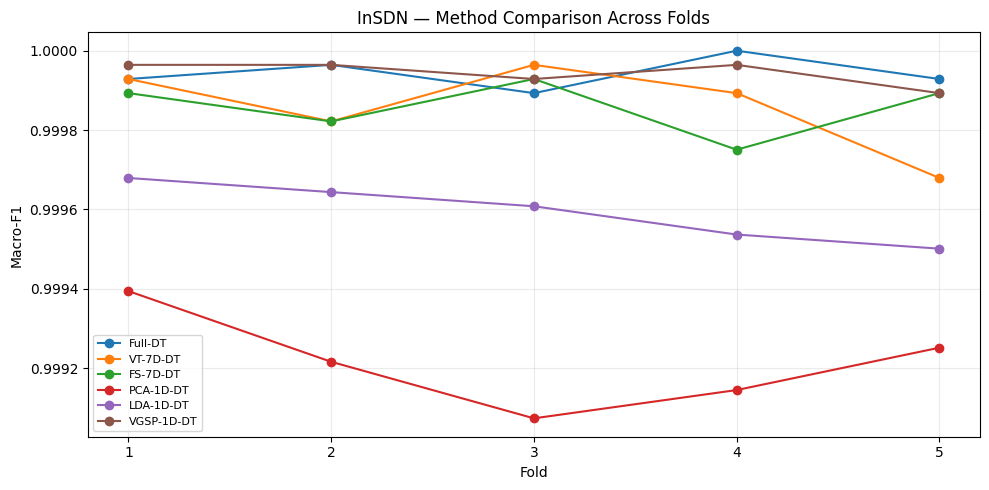

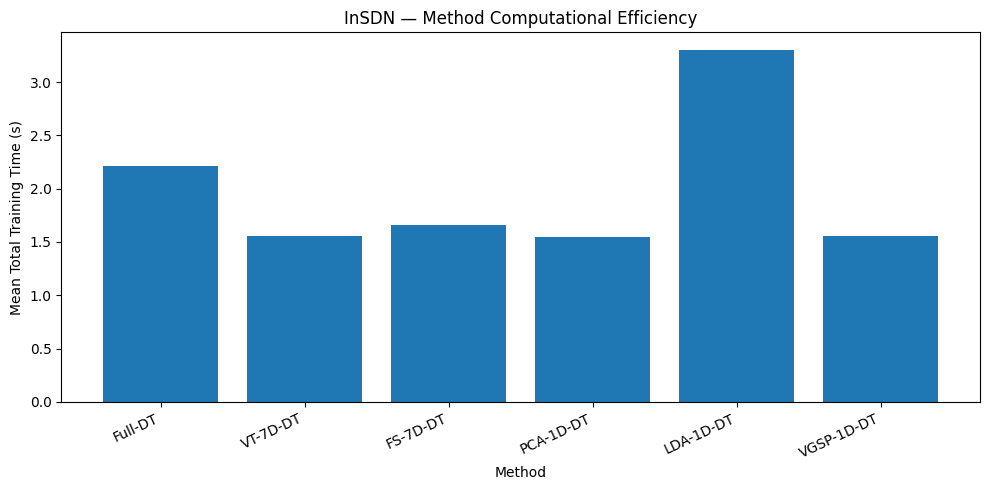

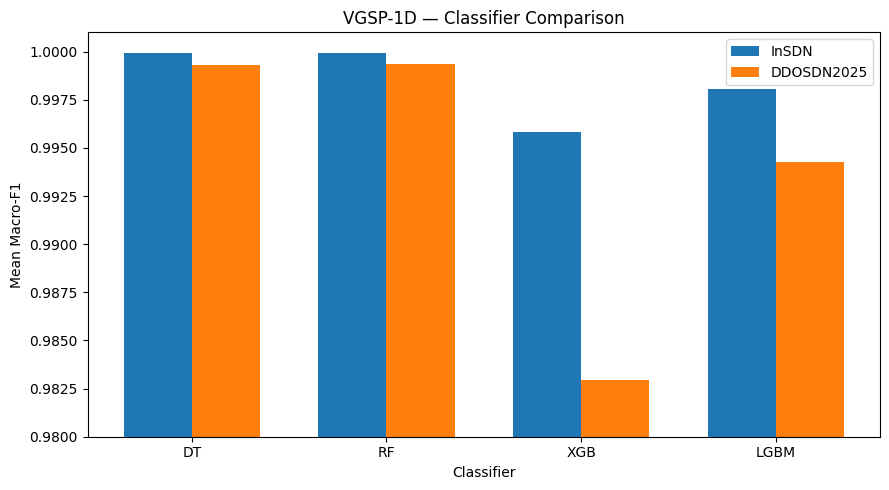

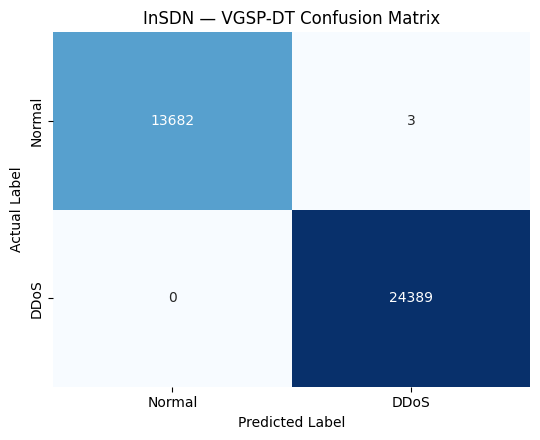

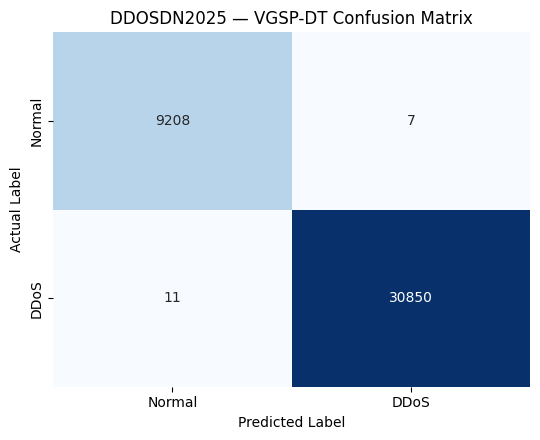


Statistical evaluation completed.



**Summary:** Exact paired Wilcoxon signed-rank testing with Holm correction was performed for 8 comparisons. No comparisons remained statistically significant at α=0.05. The analysis provides supporting evidence regarding fold-wise performance differences, subject to the limitations of five-fold CV.

In [12]:
# CELL 12: STATISTICAL EVALUATION & FINAL FIGURES
# METHOD COMPARISON + CLASSIFIER COMPARISON
# ============================================================

from itertools import product
from scipy.stats import rankdata

# ============================================================
# 1. PREPARE FOLD-WISE MACRO-F1 RESULTS
# ============================================================

method_folds = method_df.pivot(
    index="Fold",
    columns="Method",
    values="Macro-F1"
).sort_index()

classifier_folds = classifier_df.pivot(
    index="Fold",
    columns="Classifier",
    values="Macro-F1"
).sort_index()

# Ensure paired comparisons use identical fold numbers
assert method_folds.index.equals(classifier_folds.index)
assert len(method_folds) == N_FOLDS

# ============================================================
# 2. EXACT PAIRED WILCOXON
# ============================================================

def exact_wilcoxon(a, b):

    # Round differences to avoid floating-point rank issues
    d = np.round(
        np.asarray(a, dtype=float) -
        np.asarray(b, dtype=float),
        12
    )

    # Standard Wilcoxon: exclude zero differences
    d = d[d != 0]
    n = len(d)

    if n == 0:
        return 0.0, 1.0, 0

    ranks = rankdata(np.abs(d), method="average")

    total = ranks.sum()
    w_plus = ranks[d > 0].sum()
    w_obs = min(w_plus, total - w_plus)

    # Exact conditional sign enumeration
    w_values = []

    for signs in product([-1, 1], repeat=n):

        signs = np.asarray(signs)
        w = ranks[signs > 0].sum()

        w_values.append(min(w, total - w))

    p = np.mean(
        np.asarray(w_values) <= w_obs + 1e-12
    )

    return w_obs, p, n


# ============================================================
# 3. HOLM MULTIPLE-COMPARISON CORRECTION
# ============================================================

def holm_adjust(pvalues):

    pvalues = np.asarray(pvalues, dtype=float)
    m = len(pvalues)

    order = np.argsort(pvalues, kind="stable")

    adjusted_sorted = np.maximum.accumulate(
        pvalues[order] * (m - np.arange(m))
    )

    adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

    adjusted = np.empty(m)
    adjusted[order] = adjusted_sorted

    return adjusted


# ============================================================
# 4. METHOD COMPARISON (CELL 8)
# ============================================================

stat_results = []

vgsp_scores = method_folds["VGSP-1D-DT"].to_numpy()

METHOD_BASELINES = [
    "Full-DT",
    "VT-7D-DT",
    "FS-7D-DT",
    "PCA-1D-DT",
    "LDA-1D-DT"
]

for baseline in METHOD_BASELINES:

    baseline_scores = method_folds[baseline].to_numpy()

    w, p, n = exact_wilcoxon(
        vgsp_scores,
        baseline_scores
    )

    stat_results.append({
        "Group": "Method",
        "Comparison": f"VGSP-DT vs {baseline}",
        "VGSP Mean": vgsp_scores.mean(),
        "Compared Mean": baseline_scores.mean(),
        "Mean Difference": (
            vgsp_scores - baseline_scores
        ).mean(),
        "W": w,
        "n": n,
        "Exact p": p
    })


# ============================================================
# 5. CLASSIFIER COMPARISON (CELL 9)
# ============================================================

dt_scores = classifier_folds["DT"].to_numpy()

CLASSIFIER_BASELINES = ["RF", "XGB", "LGBM"]

for baseline in CLASSIFIER_BASELINES:

    baseline_scores = classifier_folds[
        baseline
    ].to_numpy()

    w, p, n = exact_wilcoxon(
        dt_scores,
        baseline_scores
    )

    stat_results.append({
        "Group": "Classifier",
        "Comparison": f"VGSP-DT vs VGSP-{baseline}",
        "VGSP Mean": dt_scores.mean(),
        "Compared Mean": baseline_scores.mean(),
        "Mean Difference": (
            dt_scores - baseline_scores
        ).mean(),
        "W": w,
        "n": n,
        "Exact p": p
    })


# ============================================================
# 6. STATISTICAL SUMMARY
# ============================================================

stat_df = pd.DataFrame(stat_results)

# Holm correction separately for each comparison family
stat_df["Holm p"] = np.nan

for group in stat_df["Group"].unique():

    mask = stat_df["Group"] == group

    stat_df.loc[mask, "Holm p"] = holm_adjust(
        stat_df.loc[mask, "Exact p"].to_numpy()
    )

stat_df["Significant (0.05)"] = (
    stat_df["Holm p"] < 0.05
)

print("\nINSDN — METHOD WILCOXON COMPARISON")

print(
    stat_df[stat_df["Group"] == "Method"]
    .drop(columns="Group")
    .round(6)
    .to_string(index=False)
)

print("\nINSDN — CLASSIFIER WILCOXON COMPARISON")

print(
    stat_df[stat_df["Group"] == "Classifier"]
    .drop(columns="Group")
    .round(6)
    .to_string(index=False)
)


# ============================================================
# 7. FIGURE 12A: METHOD MACRO-F1 ACROSS FOLDS
# ============================================================

plt.figure(figsize=(10, 5))

for method in METHOD_BASELINES + ["VGSP-1D-DT"]:

    plt.plot(
        method_folds.index,
        method_folds[method],
        marker="o",
        label=method
    )

plt.xlabel("Fold")
plt.ylabel("Macro-F1")
plt.title("InSDN — Method Comparison Across Folds")
plt.xticks(range(1, N_FOLDS + 1))
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure12a_method_folds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. FIGURE 12B: METHOD TRAINING EFFICIENCY
# ============================================================

methods = METHOD_BASELINES + ["VGSP-1D-DT"]

plt.figure(figsize=(10, 5))

plt.bar(
    methods,
    efficiency_df.loc[methods, "Total_Train_s"]
)

plt.ylabel("Mean Total Training Time (s)")
plt.xlabel("Method")
plt.title("InSDN — Method Computational Efficiency")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure12b_method_efficiency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. FIGURE 12C: VGSP CLASSIFIERS ON BOTH DATASETS
# ============================================================

classifiers = ["DT", "RF", "XGB", "LGBM"]

insdn_f1 = classifier_performance_df.loc[
    classifiers, "Macro_F1"
].to_numpy()

ddosdn_f1 = dd_classifier_performance_df.loc[
    classifiers, "Macro_F1"
].to_numpy()

x = np.arange(len(classifiers))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    insdn_f1,
    width,
    label="InSDN"
)

plt.bar(
    x + width / 2,
    ddosdn_f1,
    width,
    label="DDOSDN2025"
)

plt.xticks(x, classifiers)
plt.xlabel("Classifier")
plt.ylabel("Mean Macro-F1")
plt.ylim(0.98, 1.001)
plt.title("VGSP-1D — Classifier Comparison")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure12c_classifier_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. FIGURES 12D-E: HELD-OUT CONFUSION MATRICES
# ============================================================

for dataset_name in ["InSDN", "DDOSDN2025"]:

    result = holdout_results_df[
        (holdout_results_df["Dataset"] == dataset_name) &
        (holdout_results_df["Classifier"] == "DT")
    ].iloc[0]

    cm = np.array([
        [int(result["TN"]), int(result["FP"])],
        [int(result["FN"]), int(result["TP"])]
    ])

    plt.figure(figsize=(5.5, 4.5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Normal", "DDoS"],
        yticklabels=["Normal", "DDoS"]
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.title(f"{dataset_name} — VGSP-DT Confusion Matrix")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR /
        f"figure12_cm_{dataset_name.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 11. SAVE STATISTICAL RESULTS
# ============================================================

stat_df.to_csv(
    OUTPUT_DIR / "cell12_wilcoxon_all.csv",
    index=False
)

stat_df[stat_df["Group"] == "Method"].to_csv(
    OUTPUT_DIR / "cell12_wilcoxon_methods.csv",
    index=False
)

stat_df[stat_df["Group"] == "Classifier"].to_csv(
    OUTPUT_DIR / "cell12_wilcoxon_classifiers.csv",
    index=False
)

print("\nStatistical evaluation completed.\n")

n_comparisons = len(stat_df)
n_significant = int(stat_df["Significant (0.05)"].sum())

conclusion = (
    "No comparisons remained statistically significant"
    if n_significant == 0
    else f"{n_significant} comparisons remained statistically significant"
)

display(Markdown(
    f"**Summary:** Exact paired Wilcoxon signed-rank "
    f"testing with Holm correction was performed for "
    f"{n_comparisons} comparisons. {conclusion} "
    f"at α=0.05. The analysis provides supporting "
    f"evidence regarding fold-wise performance differences, "
    f"subject to the limitations of five-fold CV."
))


**Summary:** All Holm-adjusted p-values exceed 0.05. In method comparisons, VGSP-DT and Full-DT have the same mean Macro-F1 (0.999943), while VGSP-DT's mean is higher than the other reported baselines. In classifier comparisons, VGSP-DT and VGSP-RF yield identical fold-wise Macro-F1; adjusted p-values against XGB and LGBM are 0.1875. The analysis supports the more limited statement that VGSP-DT preserves competitive internal-validation performance with a smaller representation and lower measured training cost; it does not establish statistically significant performance superiority.

The exact paired Wilcoxon signed-rank tests showed no statistically significant differences in Macro-F1 between VGSP-DT and the evaluated feature-reduction baselines or VGSP-based classifiers after Holm correction (adjusted p > 0.05). Nevertheless, VGSP-DT achieved higher Macro-F1 scores than FS, PCA, and LDA across all five validation folds, while matching the mean performance of the full-feature Decision Tree. Among the VGSP-based classifiers, DT and RF obtained identical fold-wise Macro-F1 scores, with DT requiring substantially less training and inference time. These results support the computational efficiency of VGSP-DT while indicating that statistical superiority in classification performance was not established.

Statistical significance was assessed using the exact paired Wilcoxon signed-rank test on fold-wise Macro-F1 scores from five-fold cross-validation. Holm correction was applied separately to the method and classifier comparisons. No statistically significant differences were observed after correction (adjusted p > 0.05). Nevertheless, VGSP-DT demonstrated competitive classification performance while reducing the feature representation to a single dimension and lowering computational overhead compared with the full-feature model.

## Additional Analysis

#### 13. VGSP 1D Visualization and Comparison

To visualize and compare the one-dimensional representations generated by VGSP, PCA, and LDA using the same validation fold. This analysis examines the distribution and class separation of normal and DDoS traffic, providing visual evidence of VGSP's ability to preserve discriminative information through scalar projection.

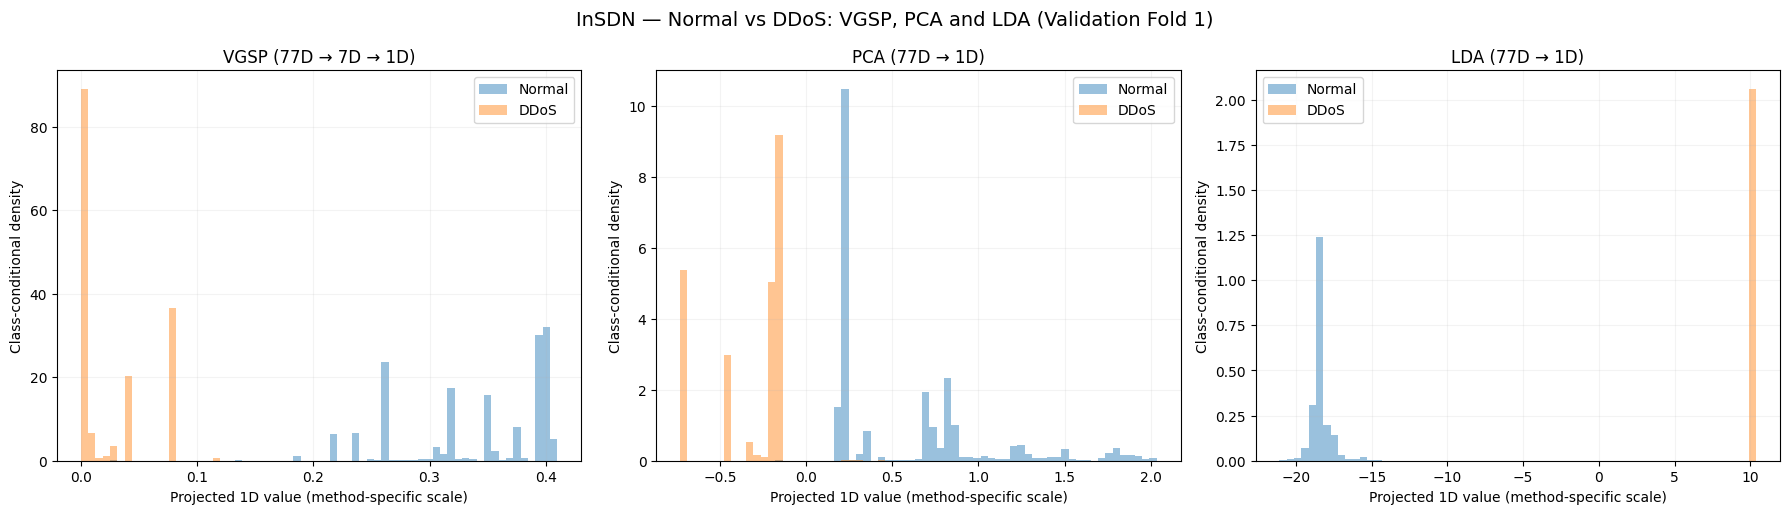

InSDN Fold 1: training=121,833, validation=30,459; k=7

PLOT COVERAGE
              Method  Class  Validation N  Fraction visible in plotted range
VGSP (77D → 7D → 1D) Normal         10948                           0.991688
VGSP (77D → 7D → 1D)   DDoS         19511                           0.993850
      PCA (77D → 1D) Normal         10948                           0.995342
      PCA (77D → 1D)   DDoS         19511                           1.000000
      LDA (77D → 1D) Normal         10948                           0.995524
      LDA (77D → 1D)   DDoS         19511                           0.998719

Figure saved: vgsp_resultsv4\cell13_insdn_vgsp_pca_lda_1d_comparison.png
VGSP visualization and comparison completed.


In [13]:
# CELL 13: VGSP vs PCA vs LDA — 1D VISUALIZATION
# ============================================================
# Thesis visualization using InSDN validation Fold 1.
# Same development data and StratifiedKFold as Cell 8.
# All preprocessing and projection fitting use training data only.
# No changes to k selection, model evaluation or held-out test.

assert "FIXED_K" in globals(), "Run Cell 6 first."
assert "datasets" in globals(), "Run Cells 2–3 first."

vis_data = datasets["InSDN"]
vis_X = vis_data["X"]
vis_y = vis_data["y"]
vis_dev = vis_data["dev_idx"]

# ------------------------------------------------------------
# 1. Use the same CV partition as Cell 8 (Fold 1)
# ------------------------------------------------------------
vis_cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

vis_train_local, vis_valid_local = next(
    vis_cv.split(vis_X.iloc[vis_dev], vis_y[vis_dev])
)

vis_train_idx = vis_dev[vis_train_local]
vis_valid_idx = vis_dev[vis_valid_local]

vis_y_train = vis_y[vis_train_idx]
vis_y_valid = vis_y[vis_valid_idx]

# ------------------------------------------------------------
# 2. Training-only preprocessing (77 numeric features)
# ------------------------------------------------------------
vis_imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

vis_A = vis_imputer.fit_transform(
    vis_X.iloc[vis_train_idx]
)
vis_B = vis_imputer.transform(
    vis_X.iloc[vis_valid_idx]
)

vis_scaler = MinMaxScaler()

vis_A = vis_scaler.fit_transform(vis_A)
vis_B = vis_scaler.transform(vis_B)

# ------------------------------------------------------------
# 3. Fit VGSP, PCA and LDA on training fold only
# ------------------------------------------------------------
vis_vgsp = fit_vgsp(
    vis_A, vis_y_train, k=FIXED_K
)

vis_pca = PCA(n_components=1).fit(vis_A)

vis_lda = LinearDiscriminantAnalysis(
    n_components=1
).fit(vis_A, vis_y_train)

# ------------------------------------------------------------
# 4. Transform training and validation data
# ------------------------------------------------------------
vis_projections = {
    f"VGSP (77D → {FIXED_K}D → 1D)": (
        transform_vgsp(vis_A, vis_vgsp).ravel(),
        transform_vgsp(vis_B, vis_vgsp).ravel()
    ),

    "PCA (77D → 1D)": (
        vis_pca.transform(vis_A).ravel(),
        vis_pca.transform(vis_B).ravel()
    ),

    "LDA (77D → 1D)": (
        vis_lda.transform(vis_A).ravel(),
        vis_lda.transform(vis_B).ravel()
    )
}

# ------------------------------------------------------------
# 5. Visualize 1D class distributions on validation data
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
vis_plot_info = []

for ax, (method_name, (z_train, z_valid)) in zip(
    axes, vis_projections.items()
):

    # Plotting limits derived from training data only.
    # Use class-wise quantiles to preserve visual readability.
    low = min(
        np.quantile(z_train[vis_y_train == label], 0.005)
        for label in (0, 1)
    )
    high = max(
        np.quantile(z_train[vis_y_train == label], 0.995)
        for label in (0, 1)
    )

    if not low < high:
        low = float(np.min(z_train))
        high = float(np.max(z_train))

    if not low < high:
        low -= 0.01
        high += 0.01

    for label, label_name in [
        (0, "Normal"),
        (1, "DDoS")
    ]:
        values = z_valid[vis_y_valid == label]

        ax.hist(
            values,
            bins=65,
            range=(low, high),
            density=True,
            alpha=0.45,
            label=label_name
        )

        vis_plot_info.append({
            "Method": method_name,
            "Class": label_name,
            "Validation N": len(values),
            "Fraction visible in plotted range": float(
                np.mean(
                    (values >= low) &
                    (values <= high)
                )
            )
        })

    ax.set_title(method_name, fontsize=12)
    ax.set_xlabel("Projected 1D value (method-specific scale)")
    ax.set_ylabel("Class-conditional density")
    ax.grid(alpha=0.15)
    ax.legend()

fig.suptitle(
    "InSDN — Normal vs DDoS: VGSP, PCA and LDA "
    "(Validation Fold 1)",
    fontsize=14
)

fig.tight_layout()

# ------------------------------------------------------------
# 6. Save visualization and plot coverage information
# ------------------------------------------------------------
vis_figure = (
    OUTPUT_DIR /
    "cell13_insdn_vgsp_pca_lda_1d_comparison.png"
)

fig.savefig(
    vis_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

vis_info_df = pd.DataFrame(vis_plot_info)

vis_info_df.to_csv(
    OUTPUT_DIR / "cell13_insdn_1d_plot_coverage.csv",
    index=False
)

print(
    f"InSDN Fold 1: "
    f"training={len(vis_train_idx):,}, "
    f"validation={len(vis_valid_idx):,}; "
    f"k={FIXED_K}"
)

print("\nPLOT COVERAGE")
print(vis_info_df.to_string(index=False))

print(f"\nFigure saved: {vis_figure}")
print("VGSP visualization and comparison completed.")


**Summary:** The 1D visualization shows that VGSP, PCA, and LDA produce different class distributions. VGSP demonstrates clear separation between normal and DDoS traffic using only seven selected features, while PCA shows greater distributional overlap and LDA exhibits strong class separation. Although LDA appears more separated visually, VGSP achieves higher Macro-F1 in the five-fold evaluation (0.999943), demonstrating its effectiveness in preserving discriminative information through a compact scalar representation.

#### 13A. VGSP Class Distribution

Class distribution of the one-dimensional scalar representation, $z$ generated by VGSP on the InSDN validation set.

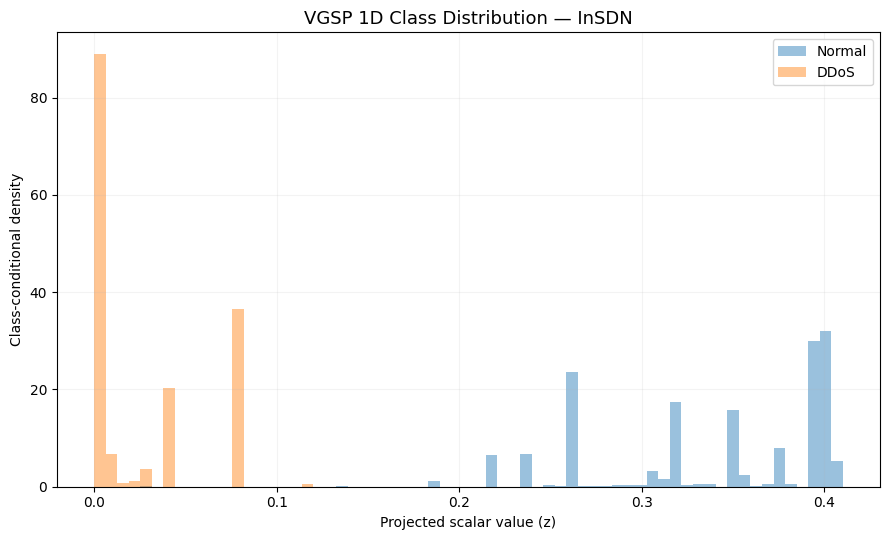

Figure saved: vgsp_resultsv4\figure4_insdn_vgsp_class_distribution.png
Selected features: 7
Validation samples: 30,459
Normal visible in plot: 99.17%
DDoS visible in plot: 99.38%


In [17]:
# VGSP ONLY — 1D CLASS DISTRIBUTION (INSDN)
# ============================================================
# Reuse VGSP projection from Cell 13.
# Validation Fold 1, no model refitting.

vgsp_key = f"VGSP (77D → {FIXED_K}D → 1D)"
z_train, z_valid = vis_projections[vgsp_key]

# Plotting range based on training data only
low = min(
    np.quantile(z_train[vis_y_train == label], 0.005)
    for label in (0, 1)
)

high = max(
    np.quantile(z_train[vis_y_train == label], 0.995)
    for label in (0, 1)
)

if not low < high:
    low = float(np.min(z_train))
    high = float(np.max(z_train))

if not low < high:
    low -= 0.01
    high += 0.01

# ============================================================
# PLOT VGSP CLASS DISTRIBUTION
# ============================================================
fig, ax = plt.subplots(figsize=(9, 5.5))

for label, label_name in [
    (0, "Normal"),
    (1, "DDoS")
]:
    values = z_valid[vis_y_valid == label]

    ax.hist(
        values,
        bins=65,
        range=(low, high),
        density=True,
        alpha=0.45,
        label=label_name
    )

ax.set_title(
    "VGSP 1D Class Distribution — InSDN",
    fontsize=13
)

ax.set_xlabel("Projected scalar value (z)")
ax.set_ylabel("Class-conditional density")

ax.grid(alpha=0.15)
ax.legend()

plt.tight_layout()

# ============================================================
# SAVE FIGURE
# ============================================================
figure_path = (
    OUTPUT_DIR /
    "figure4_insdn_vgsp_class_distribution.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Figure saved: {figure_path}")
print(f"Selected features: {FIXED_K}")
print(f"Validation samples: {len(vis_y_valid):,}")

for label, name in [(0, "Normal"), (1, "DDoS")]:
    values = z_valid[vis_y_valid == label]
    visible = np.mean(
        (values >= low) & (values <= high)
    )
    print(f"{name} visible in plot: {visible:.2%}")


#### 13B. VGSP 7D-to-1D Scalar Mapping Visualization

**Purpose:** To illustrate how the seven selected traffic features are mapped into a single one-dimensional scalar representation using CVR-proportional projection weights.

**Procedure:** Reuse the VGSP parameters estimated from the training fold in Cell 13 and select an illustrative sample from the corresponding InSDN validation fold. Display the normalized feature values, CVR scores, projection weights, and individual weighted contributions. The contributions are summed to produce a single scalar value, z, which is verified against the VGSP transformation function and visualized on a one-dimensional axis. No additional model fitting is performed.

Selected class: Normal
Validation sample index: 10
Active features: 5 / 7


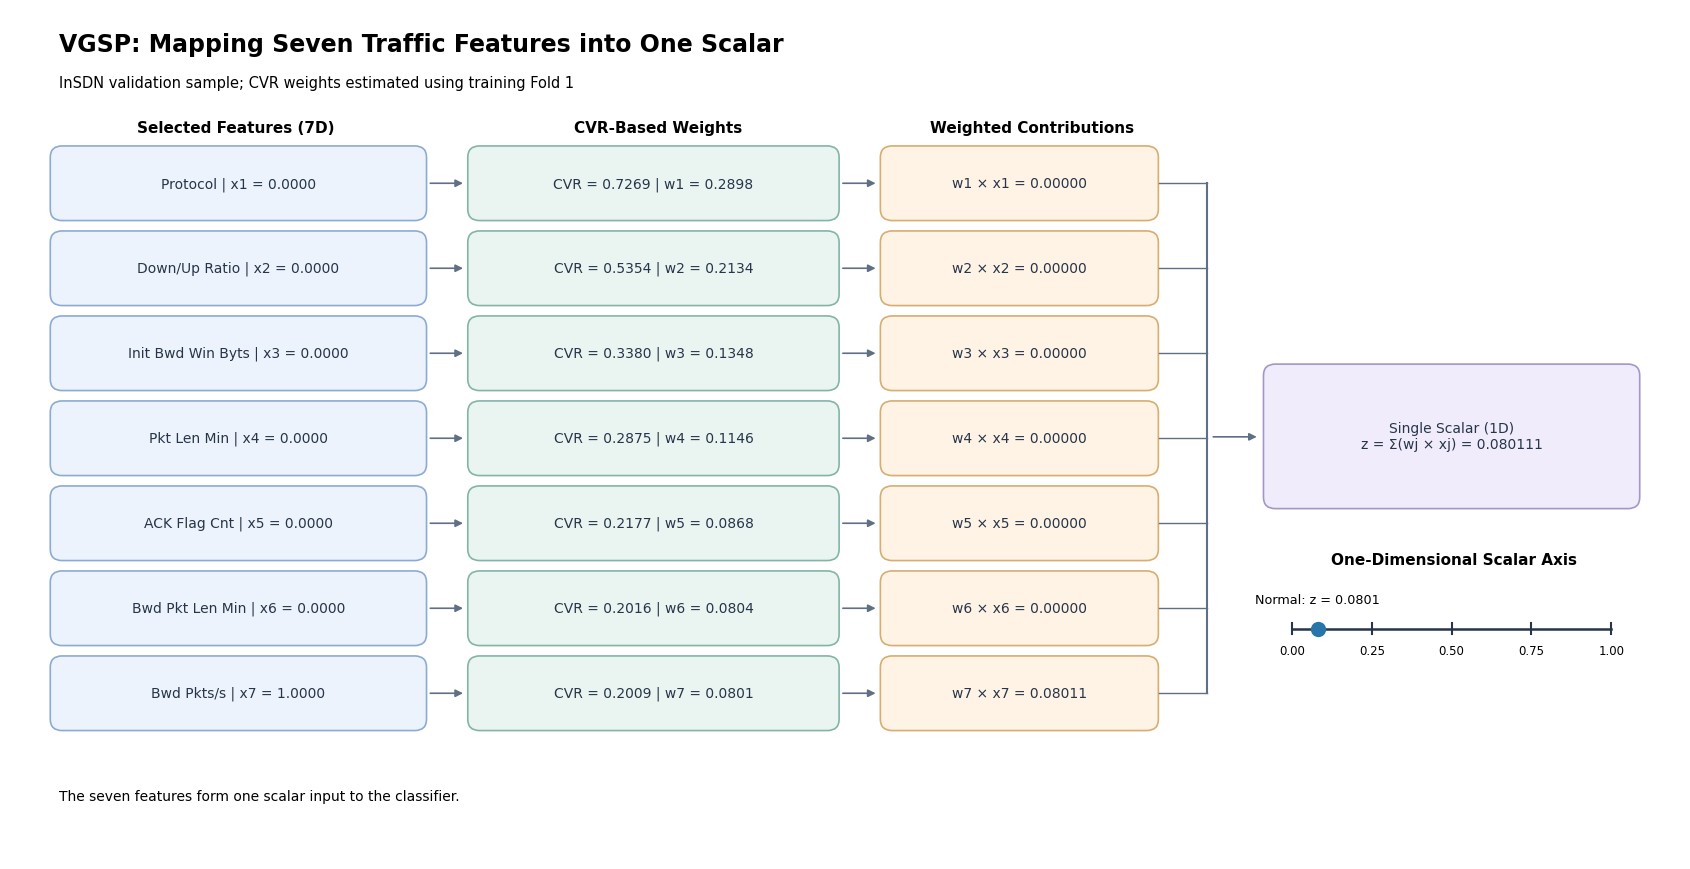

Computed scalar z : 0.08011087
VGSP function z   : 0.08011087
Figure saved      : vgsp_resultsv4\vgsp_7d_to_1d_mapping.png


In [19]:
# VGSP: 7 FEATURES -> SINGLE 1D SCALAR REPRESENTATION
# Visualization using InSDN Validation Fold 1
# Run AFTER Cell 13. No additional model fitting.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

required = [
    'vis_vgsp', 'vis_B', 'vis_X',
    'vis_y_valid', 'FIXED_K', 'transform_vgsp'
]

assert all(name in globals() for name in required), \
    "Please run Cell 13 first."

assert FIXED_K == 7

# ------------------------------------------------------------
# 1. Select an illustrative validation sample
# ------------------------------------------------------------

example_class = 0  # 0 = Normal, 1 = DDoS

# Training-derived VGSP feature indices
idx = np.asarray(vis_vgsp["indices"][:FIXED_K])

# Find validation samples belonging to the selected class
candidates = np.flatnonzero(
    vis_y_valid == example_class
)

# Count nonzero selected features after scaling
active_counts = np.count_nonzero(
    np.abs(vis_B[candidates][:, idx]) > 1e-4,
    axis=1
)

# Prefer a sample with at least five active features
eligible = candidates[active_counts >= 5]

if len(eligible) > 0:
    sample_id = int(eligible[0])
else:
    sample_id = int(candidates[np.argmax(active_counts)])

print("Selected class:", "Normal" if example_class == 0 else "DDoS")
print("Validation sample index:", sample_id)
print("Active features:", np.count_nonzero(
    np.abs(vis_B[sample_id, idx]) > 1e-4
), "/", FIXED_K)


# ------------------------------------------------------------
# 2. Prepare figure
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(17, 8.8))

ax.set_xlim(0, 17)
ax.set_ylim(0, 9)
ax.axis('off')

colors = {
    'input':   ('#edf3fc', '#8cabd3'),
    'weight':  ('#eaf5f2', '#83b4a8'),
    'product': ('#fff3e5', '#d7ad71'),
    'scalar':  ('#f1ecfb', '#a597c5')
}

def node(x0, y0, width, height, text, kind):
    fill, edge = colors[kind]

    ax.add_patch(FancyBboxPatch(
        (x0, y0),
        width, height,
        boxstyle='round,pad=0.09,rounding_size=0.12',
        facecolor=fill,
        edgecolor=edge,
        linewidth=1.2
    ))

    ax.text(
        x0 + width / 2,
        y0 + height / 2,
        text,
        ha='center',
        va='center',
        fontsize=10,
        color='#263549'
    )

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle='-|>',
        mutation_scale=11,
        linewidth=1.2,
        color='#607084'
    ))

# ------------------------------------------------------------
# 3. Titles and headings
# ------------------------------------------------------------
ax.text(
    0.5, 8.55,
    'VGSP: Mapping Seven Traffic Features into One Scalar',
    fontsize=17,
    fontweight='bold'
)

ax.text(
    0.5, 8.17,
    'InSDN validation sample; CVR weights estimated '
    'using training Fold 1',
    fontsize=10.5
)

for xpos, heading in [
    (2.3, 'Selected Features (7D)'),
    (6.6, 'CVR-Based Weights'),
    (10.4, 'Weighted Contributions')
]:
    ax.text(
        xpos, 7.7, heading,
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

# ------------------------------------------------------------
# 4. Visualize seven weighted feature contributions
# ------------------------------------------------------------
rows = np.linspace(6.85, 1.45, 7)

for j, y0 in enumerate(rows):

    node(
        0.5, y0, 3.65, 0.61,
        f'{names[j]} | x{j+1} = {x[j]:.4f}',
        'input'
    )

    node(
        4.75, y0, 3.6, 0.61,
        f'CVR = {s[j]:.4f} | w{j+1} = {w[j]:.4f}',
        'weight'
    )

    node(
        8.95, y0, 2.65, 0.61,
        f'w{j+1} × x{j+1} = {contribution[j]:.5f}',
        'product'
    )

    cy = y0 + 0.305

    arrow(4.25, cy, 4.64, cy)
    arrow(8.45, cy, 8.84, cy)

    ax.plot(
        [11.7, 12.18],
        [cy, cy],
        color='#607084',
        linewidth=1
    )

# Merge all weighted contributions
ax.plot(
    [12.18, 12.18],
    [rows[-1] + 0.305, rows[0] + 0.305],
    color='#607084',
    linewidth=1.5
)

arrow(12.22, 4.47, 12.72, 4.47)

# ------------------------------------------------------------
# 5. Final scalar representation
# ------------------------------------------------------------
node(
    12.85, 3.8, 3.65, 1.35,
    f'Single Scalar (1D)\n'
    f'z = Σ(wj × xj) = {z:.6f}',
    'scalar'
)

# ------------------------------------------------------------
# 6. Show the scalar on a 1D axis
# ------------------------------------------------------------
ax.text(
    14.7, 3.12,
    'One-Dimensional Scalar Axis',
    ha='center',
    fontweight='bold',
    fontsize=11
)

left, right, axis_y = 13.05, 16.3, 2.44

lo = min(0.0, z - 0.05)
hi = max(1.0, z + 0.05)

ax.plot(
    [left, right],
    [axis_y, axis_y],
    color='#263549',
    linewidth=1.8
)

for t in np.linspace(lo, hi, 5):
    xt = left + (t-lo)/(hi-lo)*(right-left)

    ax.plot(
        [xt, xt],
        [axis_y-0.06, axis_y+0.06],
        color='#263549'
    )

    ax.text(
        xt, axis_y-0.16,
        f'{t:.2f}',
        ha='center',
        va='top',
        fontsize=8.5
    )

point_x = left + (z-lo)/(hi-lo)*(right-left)

ax.scatter(
    [point_x], [axis_y],
    s=100,
    color='#b55447' if example_class else '#2875a9',
    zorder=5
)

ax.text(
    point_x, axis_y+0.27,
    f'{"DDoS" if example_class else "Normal"}: z = {z:.4f}',
    ha='center',
    fontsize=9.2
)

ax.text(
    0.5, 0.62,
    'The seven features form one scalar input to the '
    'classifier.',
    fontsize=10
)

# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------
fig.tight_layout()

out_path = (
    Path(OUTPUT_DIR) /
    'vgsp_7d_to_1d_mapping.png'
)

fig.savefig(
    out_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print(f'Computed scalar z : {z:.8f}')
print(f'VGSP function z   : {z_function:.8f}')
print(f'Figure saved      : {out_path}')


#### 14.VGSP-DT Visualization and Model Complexity

To visualize the final VGSP-based Decision Tree models for InSDN and DDOSDN2025 and examine their structural complexity, including tree depth, number of nodes, leaves, decision thresholds, and serialized model size. This analysis provides supporting evidence for evaluating the interpretability, compactness, and lightweight characteristics of the proposed VGSP-DT approach.

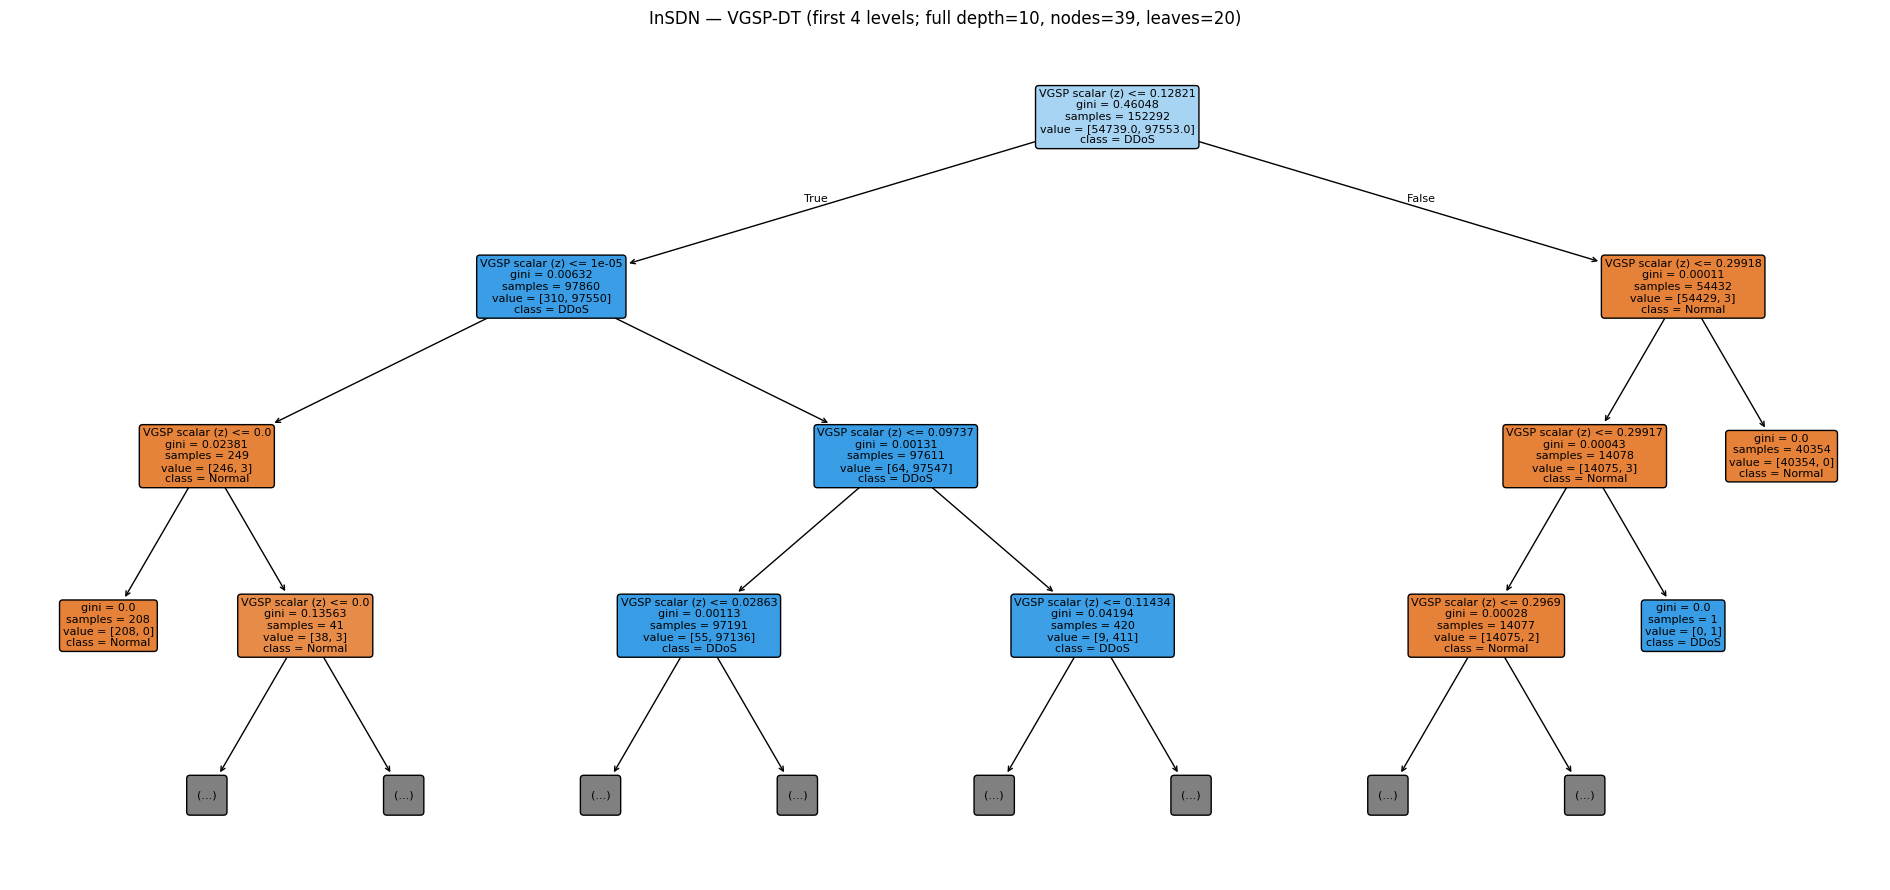

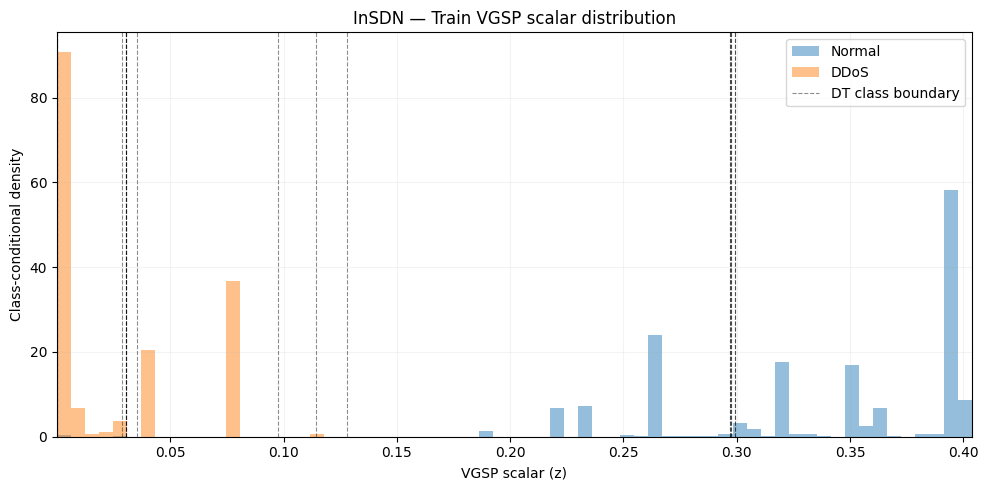

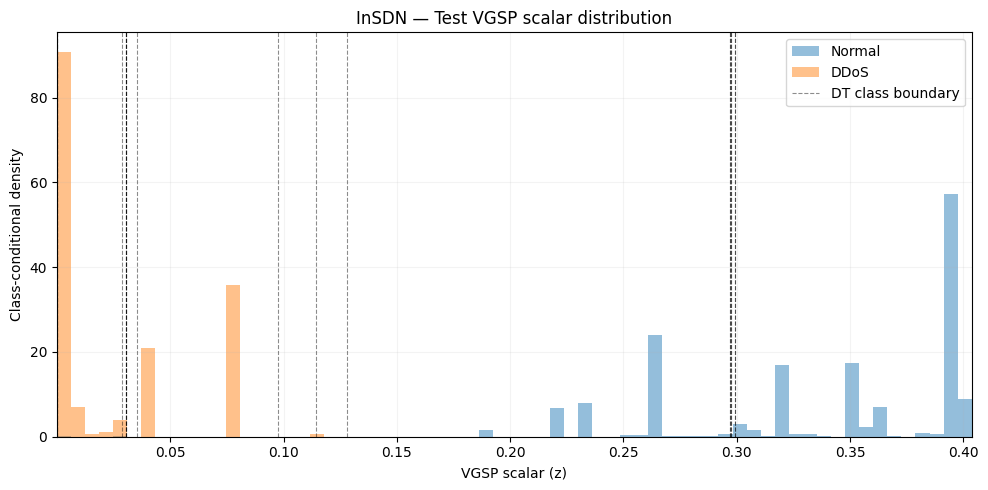

InSDN: depth=10, nodes=39, leaves=20, split thresholds=19, class boundaries in plotted range=18


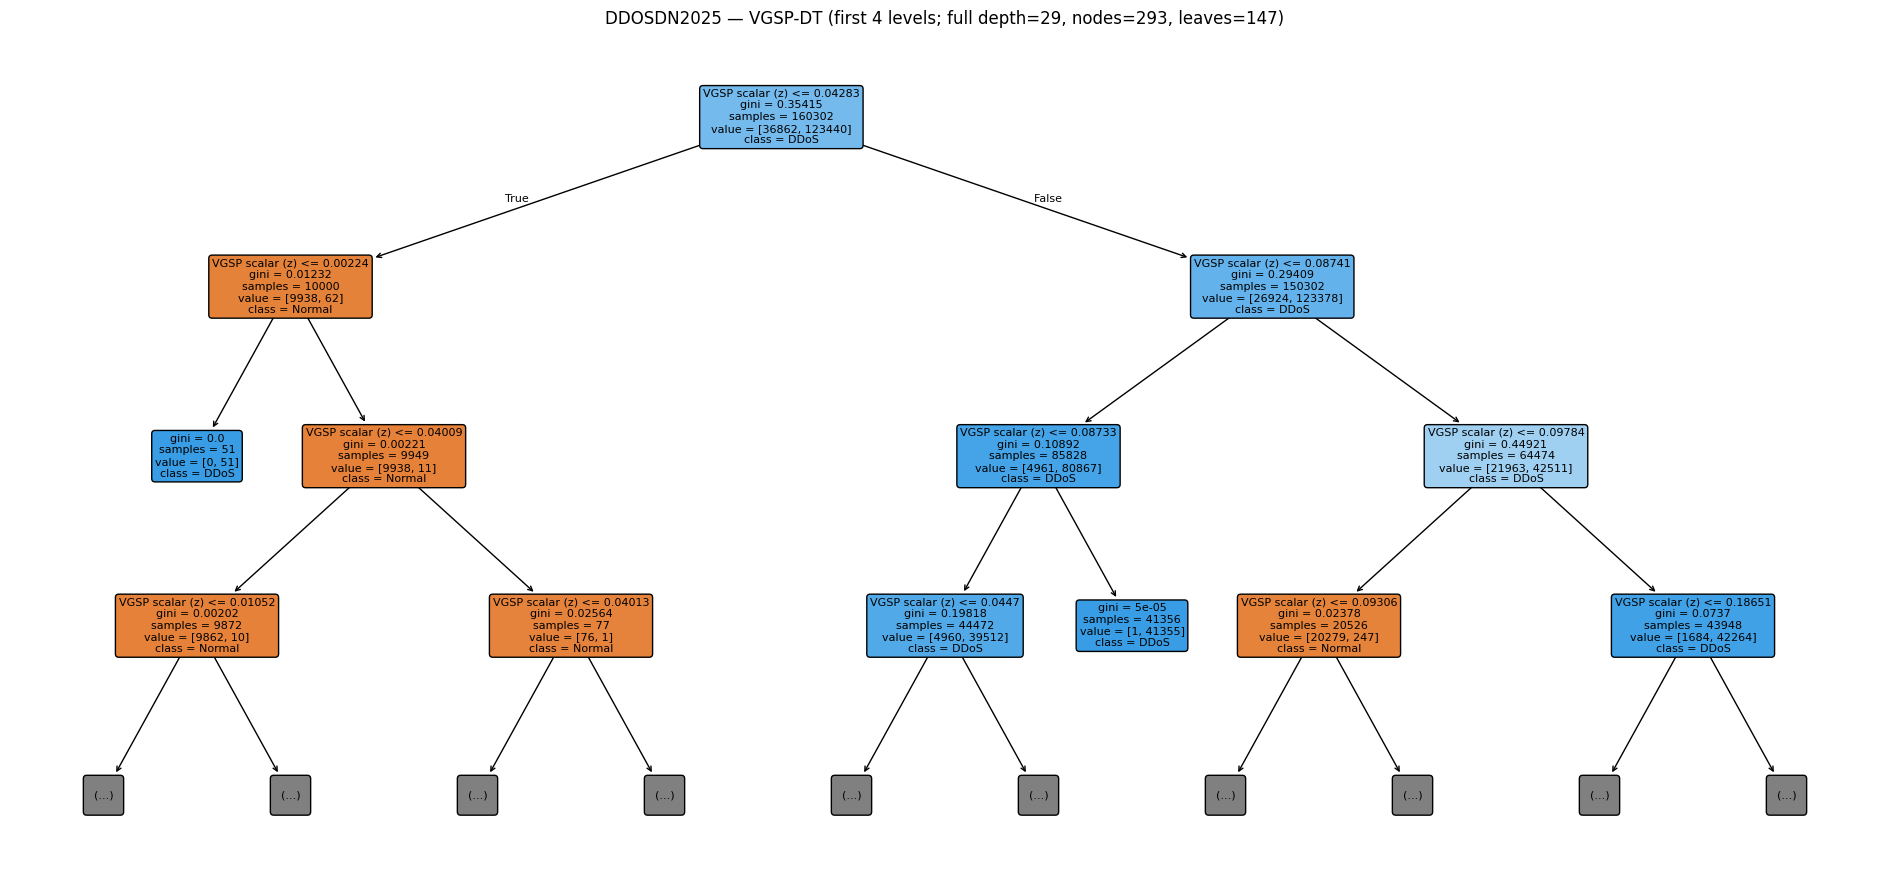

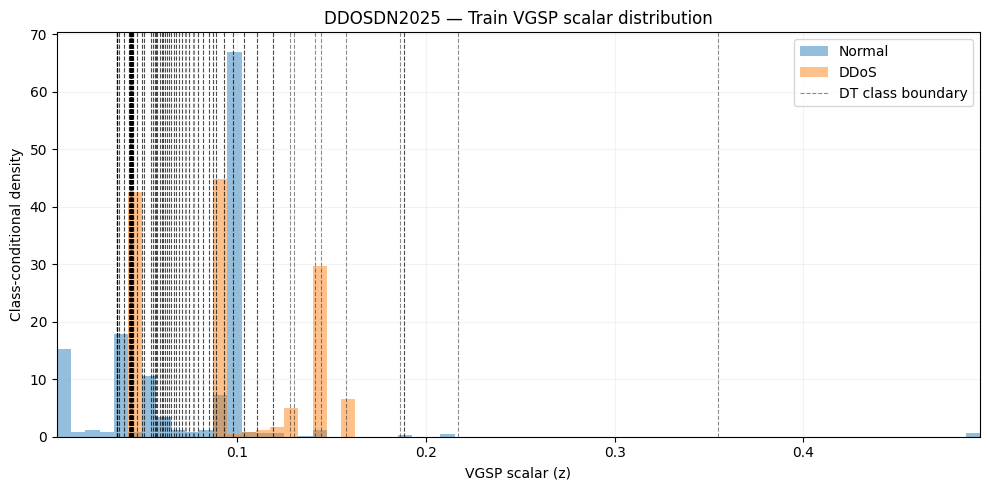

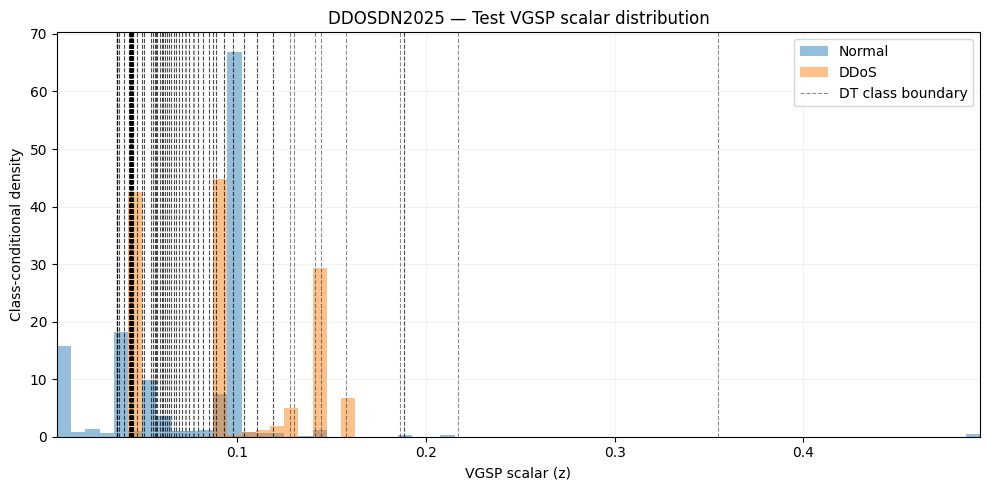

DDOSDN2025: depth=29, nodes=293, leaves=147, split thresholds=146, class boundaries in plotted range=128

FINAL HELD-OUT VGSP-DT MODEL COMPLEXITY
   Dataset  Input Features  DT Input Dimensions  Tree Depth  Tree Nodes  Tree Leaves  Split Nodes  DT Disk Size (KiB)  Bundle Disk Size (KiB)
     InSDN               7                    1          10          39           20           19            4.321000                6.300000
DDOSDN2025               7                    1          29         293          147          146           24.165000               26.144000

DT SPLIT THRESHOLDS (ROOT / FIRST LEVELS)
   Dataset  Node  Depth  Threshold (z)  Training Samples in Node
     InSDN     0      0       0.128210                    152292
     InSDN     1      1       0.000010                     97860
     InSDN     2      2       0.000000                       249
     InSDN     7      2       0.097373                     97611
     InSDN    26      1       0.299178                     5

**Summary:** The final VGSP-DT models use a single scalar input with the following complexity: **InSDN**: depth 10, 39 nodes, 20 leaves, DT storage 4.32 KiB; **DDOSDN2025**: depth 29, 293 nodes, 147 leaves, DT storage 24.17 KiB. These measurements describe the actual fitted trees and their serialized storage sizes, rather than assuming that one-dimensional input necessarily produces shallow trees.

In [15]:
# CELL 14: FINAL VGSP-DT VISUALIZATION AND MODEL COMPLEXITY
# ============================================================
# Descriptive analysis only. Reuses models fitted in Cell 11.
# No refitting, hyperparameter changes, or use of test labels to fit.

from pathlib import Path

assert "holdout_models" in globals(), "Run Cell 11 before Cell 13."
assert "FIXED_FEATURES" in globals(), "Run Cell 11 before Cell 13."

complexity_records = []
split_records = []

for dataset_name in ["InSDN", "DDOSDN2025"]:
    data = datasets[dataset_name]
    bundle = holdout_models[dataset_name]
    dt = bundle["classifiers"]["DT"]
    assert dt.n_features_in_ == 1, "The stored DT must use the VGSP scalar."

    # Reuse training-fitted transforms from Cell 11 (transform only).
    # For DDOSDN2025, rename columns exactly as in Cell 11.
    X = data["X"].rename(columns=dd_columns)[bundle["features"]]
    train_idx, test_idx = data["dev_idx"], data["test_idx"]
    y_train, y_test = data["y"][train_idx], data["y"][test_idx]

    def project_rows(rows):
        x = bundle["imputer"].transform(X.iloc[rows])
        x = bundle["scaler"].transform(x)
        return transform_vgsp(x, bundle["vgsp"]).ravel()

    z_train = project_rows(train_idx)
    z_test = project_rows(test_idx)

    # Actual, unpruned tree complexity (not the displayed max_depth=3).
    tree = dt.tree_
    n_nodes = int(tree.node_count)
    depth = int(dt.get_depth())
    n_leaves = int(dt.get_n_leaves())
    split_nodes = np.flatnonzero(tree.children_left != -1)

    # Derive node depths for split-threshold reporting.
    node_depths = np.full(n_nodes, -1, dtype=int)
    stack = [(0, 0)]
    while stack:
        node_id, level = stack.pop()
        node_depths[node_id] = level
        if tree.children_left[node_id] != -1:
            stack.append((int(tree.children_left[node_id]), level + 1))
            stack.append((int(tree.children_right[node_id]), level + 1))

    for node_id in split_nodes:
        split_records.append({
            "Dataset": dataset_name,
            "Node": int(node_id),
            "Depth": int(node_depths[node_id]),
            "Threshold (z)": float(tree.threshold[node_id]),
            "Training Samples in Node": int(tree.n_node_samples[node_id])
        })

    # Serialised disk size measures (no compression), not live RAM use.
    # Full bundle retains the input feature names and fitted parameters.
    prefix = dataset_name.lower()
    dt_path = OUTPUT_DIR / f"cell13_{prefix}_vgsp_dt.joblib"
    bundle_path = OUTPUT_DIR / f"cell13_{prefix}_vgsp_dt_bundle.joblib"

    joblib.dump(dt, dt_path, compress=0)
    joblib.dump({
        "features": bundle["features"],
        "imputer": bundle["imputer"],
        "scaler": bundle["scaler"],
        "vgsp": bundle["vgsp"],
        "classifier": dt
    }, bundle_path, compress=0)

    complexity_records.append({
        "Dataset": dataset_name,
        "Input Features": len(bundle["features"]),
        "DT Input Dimensions": dt.n_features_in_,
        "Tree Depth": depth,
        "Tree Nodes": n_nodes,
        "Tree Leaves": n_leaves,
        "Split Nodes": len(split_nodes),
        "DT Disk Size (KiB)": dt_path.stat().st_size / 1024,
        "Bundle Disk Size (KiB)": bundle_path.stat().st_size / 1024
    })

    # Figure 13A: first four levels ONLY; actual tree is not pruned.
    fig, ax = plt.subplots(figsize=(19, 9))
    plot_tree(
        dt,
        feature_names=["VGSP scalar (z)"],
        class_names=["Normal", "DDoS"],
        max_depth=3,
        filled=True,
        rounded=True,
        fontsize=8,
        precision=5,
        ax=ax
    )
    ax.set_title(
        f"{dataset_name} — VGSP-DT (first 4 levels; "
        f"full depth={depth}, nodes={n_nodes}, leaves={n_leaves})"
    )
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"cell13_{prefix}_dt_tree.png",
        dpi=240, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # Identify boundaries where the *predicted class* changes, not
    # every tree split; all thresholds are retained in the CSV.
    thresholds = np.unique(tree.threshold[split_nodes])
    z_all = np.concatenate([z_train, z_test])
    x_low, x_high = np.quantile(z_all, [0.001, 0.999])

    if not x_low < x_high:
        x_low, x_high = np.min(z_all), np.max(z_all)
    if not x_low < x_high:
        x_low -= 0.01
        x_high += 0.01

    inside = thresholds[(thresholds > x_low) & (thresholds < x_high)]
    edges = np.r_[x_low, inside, x_high]
    probes = (edges[:-1] + edges[1:]) / 2
    classes_by_region = dt.predict(probes.reshape(-1, 1))
    change_points = inside[np.flatnonzero(np.diff(classes_by_region) != 0)]

    # Figure 13B/C: original labelled train and held-out distributions.
    # Test labels are used ONLY for plotting, never for fitting.
    for partition, z, labels in [
        ("train", z_train, y_train),
        ("test", z_test, y_test)
    ]:
        fig, ax = plt.subplots(figsize=(10, 5))
        for label, name in [(0, "Normal"), (1, "DDoS")]:
            ax.hist(
                z[labels == label], bins=65, range=(x_low, x_high),
                alpha=0.48, density=True, label=name
            )
        for j, threshold in enumerate(change_points):
            ax.axvline(
                threshold, linestyle="--", linewidth=0.8,
                alpha=0.45, color="black",
                label="DT class boundary" if j == 0 else None
            )
        ax.set_xlim(x_low, x_high)
        ax.set_xlabel("VGSP scalar (z)")
        ax.set_ylabel("Class-conditional density")
        ax.set_title(
            f"{dataset_name} — {partition.title()} VGSP scalar distribution"
        )
        ax.legend()
        ax.grid(alpha=0.15)
        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / f"cell13_{prefix}_scalar_{partition}.png",
            dpi=300, bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

    print(
        f"{dataset_name}: depth={depth}, nodes={n_nodes}, "
        f"leaves={n_leaves}, split thresholds={len(split_nodes)}, "
        f"class boundaries in plotted range={len(change_points)}"
    )

# Final reporting tables. Optional CV baseline comparison REUSES Cell 8.
complexity_df = pd.DataFrame(complexity_records)
splits_df = pd.DataFrame(split_records)

complexity_df.to_csv(
    OUTPUT_DIR / "cell14_dt_complexity.csv", index=False
)
splits_df.to_csv(
    OUTPUT_DIR / "cell14_dt_split_thresholds.csv", index=False
)

print("\nFINAL HELD-OUT VGSP-DT MODEL COMPLEXITY")
print(complexity_df.round(3).to_string(index=False))

print("\nDT SPLIT THRESHOLDS (ROOT / FIRST LEVELS)")
print(
    splits_df[splits_df["Depth"] <= 2]
    .round(6).to_string(index=False)
)

if "method_df" in globals() and {"DT Nodes", "DT Depth"}.issubset(
    method_df.columns
):
    print("\nCELL 8 — DEVELOPMENT-CV TREE STRUCTURE (EXISTING RESULTS)")
    print(
        method_df.groupby("Method", sort=False)[["DT Depth", "DT Nodes"]]
        .agg(["mean", "std"]).round(2).to_string()
    )

print("\nVGSP-DT visualization completed.\n")

parts = []

for _, r in complexity_df.iterrows():

    parts.append(
        f"**{r['Dataset']}**: depth "
        f"{int(r['Tree Depth'])}, "
        f"{int(r['Tree Nodes'])} nodes, "
        f"{int(r['Tree Leaves'])} leaves, "
        f"DT storage {r['DT Disk Size (KiB)']:.2f} KiB"
    )

display(Markdown(
    "**Summary:** The final VGSP-DT models use a "
    "single scalar input with the following complexity: "
    + "; ".join(parts)
    + ". These measurements describe the actual fitted "
      "trees and their serialized storage sizes, "
      "rather than assuming that one-dimensional input "
      "necessarily produces shallow trees."
))
